# Gradient System Engineering

**Part:** B – Hardware (deep dive) · **Reading time:** ~90 min · **Pass 1 overview:** [The MRI Scanner](../pass1_big_picture/P1.2_The_MRI_Scanner.ipynb) · **Refreshers you may want:** [Magnetism from currents (Biot–Savart)](../refreshers/RP1_Magnetism_from_Currents.ipynb), [Induction & RF](../refreshers/RP2_Induction_and_RF.ipynb), [ODEs for MRI](../refreshers/RM1_ODEs_for_MRI.ipynb), [Fourier properties (convolution)](../refreshers/RM4_Fourier_Properties.ipynb)

**Why this chapter matters.** Every image you will ever reconstruct is encoded by the gradient coils: the gradient waveform $\vec G(t)$ *is* the k-space trajectory ([K-space](../pass2_deep_dive/F2_K-space.ipynb)). How strong the gradient can be ($G_{max}$) and how fast it can change ($SR$) sets the minimum echo time, the echo spacing of EPI, the achievable diffusion weighting and the resolution per unit time. Behind those two numbers hides a remarkable piece of engineering: copper windings carrying hundreds of amperes, switched by kilovolt amplifiers in a fraction of a millisecond, inside a 3 T magnet that shakes them with kilonewton forces — while the patient's nerves, ears and the cryostat all set their own limits. This chapter derives these limits with simple math and simulates each of them in Python.

This chapter builds on [B1 MRI System](../pass2_deep_dive/B1_MRI_System.ipynb) (the components) and [B2 Magnetic Fields in MRI](../pass2_deep_dive/B2_Magnetic_Fields_in_MRI.ipynb) (Biot–Savart, fields of loops). The main magnet is covered in [B3 Main Magnet Engineering](../pass2_deep_dive/B3_Main_Magnet_Engineering.ipynb), safety limits in [B6 MRI Safety](../pass2_deep_dive/B6_MRI_Safety.ipynb).

## Learning goals

1. Explain what a gradient field is physically (a $B_z$ that varies linearly in space) and why Maxwell's equations force extra "concomitant" field components to exist.
2. Describe the classic coil designs — Maxwell pair (z), Golay saddle (x, y) — and modern distributed ("fingerprint") windings from the target-field method; compute their fields with Biot–Savart.
3. Characterize a gradient coil as an electrical load (efficiency $\eta$, inductance $L$, resistance $R_{coil}$) and derive the slew-rate limit $SR_{max}=\eta\,(V_{max}-R_{coil}I_c)/L$ from the amplifier voltage.
4. Design minimum-time trapezoidal and triangular gradient lobes for a required area, and estimate echo spacings.
5. Estimate gradient heating ($I_{rms}^2 R_{coil}$) and the required cooling.
6. Model eddy currents as a sum of decaying exponentials and design a pre-emphasis filter that cancels them; explain active shielding.
7. Quantify gradient non-linearity (geometric distortion) and concomitant fields.
8. Model peripheral nerve stimulation (rheobase, chronaxie) and acoustic noise (Lorentz forces, mechanical resonances), and explain why they — not the amplifier — often limit modern scanners.

## Symbols used in this chapter

| Symbol | Meaning (plain words) | SI unit | Typical value / remark |
|---|---|---|---|
| $\vec r=[x,y,z]^T$ | position; $z$ along $B_0$ (bore axis) | m | imaging region $\lvert\vec r\rvert\lesssim 0.25$ m |
| $\rho_\perp=\sqrt{x^2+y^2}$ | distance from the bore axis | m | |
| $t$, $\tau$ | time; $\tau$ = dummy integration variable | s | |
| $B_0$ | main static field (along $z$) | T | 0.55, 1.5, 3, 7 T |
| $\vec B=[B_x,B_y,B_z]^T$ | magnetic flux density ("field") | T | |
| $B_z(\vec r,t)$ | $z$-component of the field (the only one that matters to first order) | T | |
| $\vec G=[G_x,G_y,G_z]^T$ | gradient: rate of change of $B_z$ in space, $B_z=B_0+\vec G\cdot\vec r$ | T/m | 20–80 mT/m clinical |
| $G_{max}$ | maximum gradient amplitude per axis | T/m | 40–80 mT/m clinical; 200–500 mT/m research |
| $SR$, $SR_{max}$ | slew rate $=dG/dt$; its maximum | T/m/s | 100–200 T/m/s clinical |
| $t_r$ | rise (ramp) time of a gradient lobe, $t_r=G/SR$ | s | 0.1–1 ms |
| $t_{flat}$ | flat-top duration of a trapezoid | s | |
| $A$ | gradient area $\int G\,dt$ of a lobe (sets the k-space step) | T·s/m | $10^{-5}$ T s/m ≈ 10 mT·ms/m |
| $k$, $\vec k$ | k-space position, $\vec k=\bar\gamma\int\vec G\,dt$ | m⁻¹ | |
| $\gamma$, $\bar\gamma=\gamma/2\pi$ | gyromagnetic ratio (rad/s/T) and gamma-bar (Hz/T) | rad s⁻¹ T⁻¹, Hz/T | $\bar\gamma=42.58$ MHz/T for ¹H |
| $\delta$ | spatial resolution (pixel size) | m | 1 mm |
| $FOV$ | field of view | m | 0.24 m |
| $t_{esp}$ | echo spacing in EPI | s | 0.4–1 ms |
| $I_c$ | coil current (subscript $c$ to avoid a clash with spin number $I$) | A | 100–1000 A |
| $N_t$ | number of turns of a winding | – | 10–30 per quadrant |
| $a$ | coil (winding) radius | m | 0.3–0.35 m whole-body, ~0.2 m head |
| $d$ | separation of the two loops of a Maxwell pair | m | $\sqrt3\,a$ |
| $\eta$ | gradient efficiency $=G/I_c$ | T/m/A | 0.05–0.3 mT/m/A |
| $L$ | coil inductance | H | 0.3–1.5 mH |
| $R_{coil}$ | coil resistance (subscript to avoid clash with acceleration $R$) | Ω | 0.05–0.2 Ω |
| $V$, $V_{max}$ | amplifier output voltage; its maximum | V | 1–2.5 kV |
| $I_{max}$ | amplifier current limit | A | 500–1000 A |
| $E_{mag}=\tfrac12 LI_c^2$ | magnetic energy stored in the coil | J | ~300 J |
| $\eta^2/L$ | coil figure of merit (independent of number of turns) | T² m⁻² A⁻² H⁻¹ | |
| $I_{rms}$ | root-mean-square current over a sequence | A | |
| $P$ | electrical power dissipated as heat, $P=I_{rms}^2R_{coil}$ | W | 1–30 kW |
| $\dot m$, $c_p$ | cooling-water mass flow; specific heat of water | kg/s, J/(kg K) | $c_p=4186$ |
| $\Delta T$, $T_{coil}$ | temperature rise; coil temperature | K | |
| $C_{th}$, $R_{th}$ | thermal capacity, thermal resistance (lumped model) | J/K, K/W | |
| $\alpha_n$, $\tau_n$ | relative amplitude and time constant of eddy-current term $n$ | –, s | 0.1–5 %; 0.1–100 ms |
| $h_e(t)$ | eddy-current response to a unit gradient step | – | |
| $\beta_n$, $\tau_n'$ | pre-emphasis amplitudes and time constants | –, s | |
| $s$ | Laplace variable (complex frequency; only in an optional box) | s⁻¹ | $s=i2\pi f$ for sinusoids |
| $dB/dt$ | rate of change of the field seen by tissue | T/s | 10–100 T/s |
| $t_s$ | stimulus duration (for a ramp: $t_r$) | s | |
| $b$ | rheobase: $dB/dt$ threshold for very long stimuli | T/s | ≈ 20 T/s (IEC model) |
| $c_{ch}$ | chronaxie: duration at which threshold $=2b$ | s | ≈ 0.36 ms (IEC model, nerves) |
| $\tau_m$ | membrane time constant of the nerve model, $c_{ch}=\tau_m\ln2$ | s | ≈ 0.5 ms |
| $u(t)$ | normalized nerve-membrane "depolarization" in the leaky-integrator model | – | fires at 1 |
| $\Delta G_{min}$, $SR_{min}$ | PNS threshold parameters in gradient units | T/m, T/m/s | ~30 mT/m, ~80 T/m/s |
| $\vec F$ | Lorentz force on a wire, $\vec F=I_c\,\vec\ell\times\vec B_0$ | N | kN |
| $\vec\ell$ | wire segment vector (length and direction) | m | |
| $p$, $L_p$ | sound pressure; sound pressure level $L_p=20\log_{10}(p/20\,\mu\text{Pa})$ | Pa, dB | 100–120 dB(A) |
| $H_{ac}(f)$ | acoustic transfer function (sound per unit gradient at frequency $f$) | Pa/(T/m) | resonances at 0.5–3 kHz |
| $f$ | frequency | Hz | |
| $\Delta f_{cc}$ | concomitant-field frequency offset | Hz | |
| $\mu_0$ | vacuum permeability | T m/A | $4\pi\times10^{-7}$ |
| $\psi(\varphi,z)$ | stream function of a surface current on a cylinder; wires follow its contours | A | |
| $\varphi$ | azimuthal angle around the bore | rad | |
| $\vec K$ | surface current density | A/m | |
| $\lambda_{reg}$ | regularization weight in the target-field design | – | |

> **⚠️ Common confusion:** $\tau$ alone is a dummy integration variable; time *constants* always carry a subscript ($\tau_n$, $\tau_m$). $R_{coil}$ (resistance) is not the acceleration factor $R$. $I_c$ (current) is not the spin number $I$. $L$ is inductance, $L_p$ a sound level, and the coil length is written $\ell$.

In [1]:
import sys, os
sys.path.insert(0, os.path.abspath(".."))   # make ../mri_tools.py importable
import numpy as np
import matplotlib.pyplot as plt
import mri_tools as mt
mt.setup_plots()
%matplotlib inline

## 1. What a gradient field is

The gradient coils add a small field to $B_0$ whose **z-component** changes linearly with position:

$$B_z(\vec r,t) = B_0 + G_x(t)\,x + G_y(t)\,y + G_z(t)\,z = B_0 + \vec G(t)\cdot\vec r .$$

In words: the field along the bore axis is no longer the same everywhere; it is a little larger on one side of the scanner and a little smaller on the other, and the "tilt" of this ramp is the gradient $\vec G$.

where $B_0$ is the static main field [T], $\vec G=[G_x,G_y,G_z]^T$ the gradient [T/m], $\vec r=[x,y,z]^T$ the position [m] ($z$ along the bore). Note that $G_x$ is *not* a field pointing along $x$ — it is the rate at which $B_z$ changes as you move along $x$: $G_x=\partial B_z/\partial x$.

Because the Larmor frequency follows the field, $f(\vec r)=\bar\gamma B_z(\vec r)$, a gradient turns position into frequency — that is all of spatial encoding ([Spatial Encoding](../pass2_deep_dive/F1_Spatial_Encoding.ipynb)). Let us put numbers on it.

In [2]:
G = 40e-3            # gradient amplitude [T/m]  (40 mT/m)
x_edge = 0.25        # 25 cm from isocenter [m]
B0 = 3.0             # [T]
dB = G * x_edge      # extra field at the edge [T]
print(f"Extra field at x = {x_edge*100:.0f} cm: {dB*1e3:.1f} mT = {dB/B0*1e6:.0f} ppm of B0")
print(f"Frequency offset there: {mt.GAMMA_BAR*dB/1e3:.0f} kHz  (Larmor frequency itself: {mt.larmor_frequency(B0)/1e6:.1f} MHz)")

Extra field at x = 25 cm: 10.0 mT = 3333 ppm of B0
Frequency offset there: 426 kHz  (Larmor frequency itself: 127.7 MHz)


The gradient field is tiny compared with $B_0$ (≈ 0.3 %), but it shifts the frequency by hundreds of kHz — enormous compared with the ~Hz linewidths that matter in MRI. That is why gradients must be *accurate*: an error of 0.1 % of the gradient is still ~400 Hz at the edge of the FOV.

> **🧭 Intuition:** Only $B_z$ matters because $B_0$ is huge. Adding a small transverse component $B_x$ to a 3 T field tilts the total vector but barely changes its length: $|\vec B|=\sqrt{(B_0+B_z')^2+B_x^2}\approx B_0+B_z'+B_x^2/(2B_0)$. The transverse part only enters at second order — but it does enter; we come back to it in Section 9 (concomitant fields).

## 2. Coil designs

All designs below are just clever arrangements of current-carrying wire. The field of each wire piece follows the **Biot–Savart law**

$$d\vec B(\vec r) = \frac{\mu_0 I_c}{4\pi}\,\frac{d\vec\ell\times(\vec r-\vec r')}{|\vec r-\vec r'|^3},$$

In words: every short piece of wire $d\vec\ell$ at position $\vec r'$ carrying current $I_c$ produces a field at $\vec r$ that falls off with the square of the distance and points perpendicular to both the wire and the line joining them; the total field is the sum (integral) over all pieces.

where $\mu_0=4\pi\times10^{-7}$ T m/A is the vacuum permeability, $I_c$ [A] the current, $d\vec\ell$ [m] a wire element, $\vec r'$ its position.

> **🔁 Refresher:** If the Biot–Savart law is new, see [Magnetism from currents](../refreshers/RP1_Magnetism_from_Currents.ipynb) and the coil-field section of [B2 Magnetic Fields in MRI](../pass2_deep_dive/B2_Magnetic_Fields_in_MRI.ipynb). `mt.loop_coil_field` implements it for circular loops.

`mri_tools` only provides circular loops, so we define a small helper for an arbitrary polygonal wire path (needed for saddle coils and fingerprint windings). It is the same formula, summed over straight segments.

In [3]:
def wire_field(points, path, current=1.0, chunk=2048):
    """Biot-Savart field [T] of a polygonal wire (path: (S+1, 3) vertices [m]) at points (..., 3) [m].

    Each straight segment is approximated by its midpoint: dB = mu0 I/(4 pi) dl x R / |R|^3.
    Same method as mt.loop_coil_field, but for any wire shape."""
    pts = np.asarray(points, float)
    P = np.asarray(path, float)
    mid, dl = 0.5 * (P[1:] + P[:-1]), P[1:] - P[:-1]
    flat = pts.reshape(-1, 3)
    B = np.zeros_like(flat)
    for i in range(0, flat.shape[0], chunk):
        Rv = flat[i:i + chunk, None, :] - mid[None]
        Rn = np.maximum(np.linalg.norm(Rv, axis=-1, keepdims=True), 1e-4)   # avoid the singularity on the wire
        B[i:i + chunk] = (mt.MU0 * current / (4 * np.pi) * np.cross(dl[None], Rv) / Rn**3).sum(axis=1)
    return B.reshape(pts.shape)

# sanity check against the circular-loop helper: field at the centre of a loop, mu0 I / (2a)
a_test = 0.3
phi = np.linspace(0, 2 * np.pi, 401)
loop_path = np.stack([a_test * np.cos(phi), a_test * np.sin(phi), 0 * phi], -1)
print("wire_field:", wire_field([[0, 0, 0]], loop_path)[0, 2], " T/A;  theory mu0/(2a):", mt.MU0 / (2 * a_test))

wire_field: 2.094502767127289e-06  T/A;  theory mu0/(2a): 2.0943951023931957e-06


### 2.1 The z-gradient: Maxwell pair

Take two coaxial loops of radius $a$ at $z=\pm d/2$ with **opposite** currents. Each loop on its own gives the on-axis field (see [B2](../pass2_deep_dive/B2_Magnetic_Fields_in_MRI.ipynb))

$$B_z^{loop}(z) = \frac{\mu_0 I_c a^2}{2\,(a^2+z^2)^{3/2}} .$$

In words: a loop's field is strongest at its centre and falls off along the axis over a distance of about one radius.

With opposite currents, the two bumps subtract: at the centre they cancel ($B_z=0$), above the centre the upper loop wins, below the lower one — a field that rises through zero, i.e. a z-gradient. Expanding the sum in a Taylor series around $z=0$, only odd powers survive (by symmetry):

$$B_z(z) = G_z z + c_3 z^3 + c_5 z^5+\dots$$

In words: the field is a straight line (the gradient we want) plus "bending" terms; the $z^3$ term is the largest error.

where $c_3, c_5$ [T/m³, T/m⁵] are coefficients that depend on $a$ and $d$. James Clerk Maxwell noticed that $c_3=0$ exactly when $d=\sqrt3\,a$. Then the gradient at the centre is

$$G_z = \frac{3\mu_0 I_c\,a^2 d}{2\,(a^2+d^2/4)^{5/2}}\Big|_{d=\sqrt3 a} = \frac{48\sqrt3}{49\sqrt7}\,\frac{\mu_0 I_c}{a^2}\approx 0.641\,\frac{\mu_0 I_c}{a^2}.$$

In words: the gradient grows with current and falls with the **square** of the coil radius — a coil twice as large needs four times the current for the same gradient.

<details><summary><b>📐 Derivation (optional)</b></summary>

Differentiate the loop field: $\frac{d}{dz}B_z^{loop}=-\frac{3\mu_0I_ca^2 z}{2(a^2+z^2)^{5/2}}$.
The upper loop at $z=+d/2$ with current $+I_c$ contributes $B^{loop}(z-d/2)$, the lower loop with $-I_c$ contributes $-B^{loop}(z+d/2)$. At $z=0$:
$G_z=\frac{dB_z}{dz}\big|_0 = -\frac{3\mu_0I_ca^2(-d/2)}{2(a^2+d^2/4)^{5/2}}+\frac{3\mu_0I_ca^2(d/2)}{2(a^2+d^2/4)^{5/2}}=\frac{3\mu_0I_ca^2d}{2(a^2+d^2/4)^{5/2}}$.
Setting the third derivative at $z=0$ to zero gives $4z^2=3a^2$ evaluated at the loop position $z=d/2$, i.e. $d=\sqrt3\,a$. Inserting: $a^2+3a^2/4=7a^2/4$, $(7/4)^{5/2}=49\sqrt7/32$, so $G_z = \frac{3\sqrt3\cdot 32}{2\cdot 49\sqrt7}\frac{\mu_0I_c}{a^2}=\frac{48\sqrt3}{49\sqrt7}\frac{\mu_0I_c}{a^2}\approx0.641\,\mu_0I_c/a^2$.

</details>

Let us check this with Biot–Savart, comparing the Maxwell spacing with a "wrong" spacing $d=a$.

$d=\sqrt{3}\,a$ (Maxwell)   : G = 8.96 uT/m per A  (formula for Maxwell: 8.95)
$d=a$                       : G = 11.99 uT/m per A  (formula for Maxwell: 8.95)
$d=2.5a$                    : G = 4.98 uT/m per A  (formula for Maxwell: 8.95)


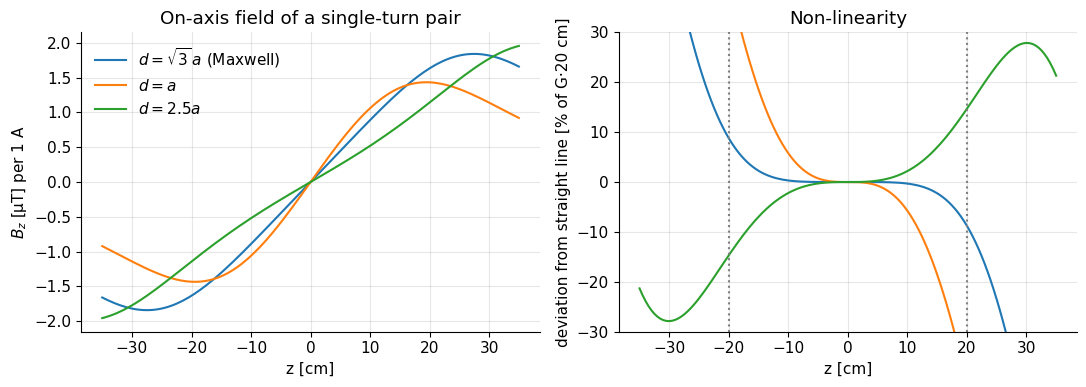

In [4]:
a = 0.30                                   # loop radius [m]
z = np.linspace(-0.35, 0.35, 141)          # positions along the bore axis [m]
pts = np.stack([0 * z, 0 * z, z], -1)

fig, ax = plt.subplots(1, 2, figsize=(11, 4))
for d, lab in [(np.sqrt(3) * a, r"$d=\sqrt{3}\,a$ (Maxwell)"), (1.0 * a, r"$d=a$"), (2.5 * a, r"$d=2.5a$")]:
    B = (mt.loop_coil_field(pts, a, +1.0, center=(0, 0, +d / 2))
         + mt.loop_coil_field(pts, a, -1.0, center=(0, 0, -d / 2)))      # 1 A, opposite currents
    G0 = np.gradient(B[:, 2], z)[len(z) // 2]                           # gradient at the centre [T/m per A]
    ax[0].plot(z * 100, B[:, 2] * 1e6, label=lab)
    ax[1].plot(z * 100, (B[:, 2] - G0 * z) / (G0 * 0.2) * 100, label=lab)   # error relative to G0*20 cm
    print(f"{lab:28s}: G = {G0*1e6:.2f} uT/m per A  (formula for Maxwell: {0.641*mt.MU0/a**2*1e6:.2f})")
ax[0].set(xlabel="z [cm]", ylabel=r"$B_z$ [µT] per 1 A", title="On-axis field of a single-turn pair")
ax[1].set(xlabel="z [cm]", ylabel="deviation from straight line [% of G·20 cm]", title="Non-linearity", ylim=(-30, 30))
for x_ in (-20, 20):
    ax[1].axvline(x_, color="gray", ls=":")
ax[0].legend(); plt.tight_layout(); plt.show()

The Maxwell spacing (blue) stays within a few percent of a straight line out to ±20 cm (dotted lines), whereas the other spacings bend much earlier — exactly the cancellation of the $z^3$ term.

> **🔧 Engineering reality:** A single turn gives only ~9 µT/m per ampere. To reach 40 mT/m you would need ~4500 A — so real coils use many turns ($N_t$ ≈ 10–30), and the gradient per ampere $\eta$ scales with $N_t$. Real z-coils also replace the two concentrated loops by a *distributed* set of loops whose spacing is optimized (Section 2.3), which extends the linear region and lowers inductance.

### 2.2 The transverse gradients: Golay (saddle) coils

For $G_x$ we need $B_z$ (still along the bore!) to change with $x$. Loops coaxial with the bore cannot do that by symmetry. The classic solution (Golay, 1958) uses four **saddle coils** on the cylinder: arcs spanning 120° at $z=\pm0.389a$ (the "inner" arcs that produce the gradient) and return arcs far away at $z=\pm2.57a$, connected by straight wires along $z$. Two saddles sit on the $+x$ side, two on the $-x$ side with reversed current. The $G_y$ coil is the same thing rotated by 90°.

Golay coil, single turn, a = 0.3 m: Gx = 10.23 uT/m per A
deviation from linear at x = 20 cm: -17 %


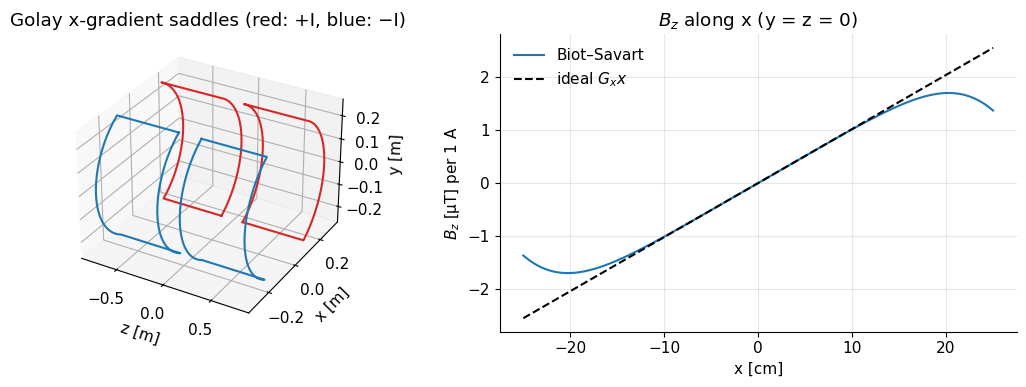

In [5]:
def saddle(a, z1, z2, phi_c, span=np.deg2rad(120), n=80):
    """One saddle loop on a cylinder of radius a: arc at z1 (phi increasing), straight to z2,
    arc back at z2, straight back to the start. phi_c = angular centre of the saddle [rad]."""
    ph = np.linspace(phi_c - span / 2, phi_c + span / 2, n)
    arc1 = np.stack([a * np.cos(ph), a * np.sin(ph), np.full(n, z1)], -1)
    arc2 = arc1[::-1].copy(); arc2[:, 2] = z2
    return np.vstack([arc1, arc2, arc1[:1]])

def golay_paths(a):
    """List of (path, sign) for the four saddles of an x-gradient Golay coil."""
    return [(saddle(a, s * 0.389 * a, s * 2.57 * a, pc), sign)
            for pc, sign in [(0.0, +1), (np.pi, -1)] for s in (+1, -1)]

a = 0.30
x = np.linspace(-0.25, 0.25, 101)
pts_x = np.stack([x, 0 * x, 0 * x], -1)
Bz = sum(sign * wire_field(pts_x, p)[:, 2] for p, sign in golay_paths(a))
Gx0 = np.gradient(Bz, x)[50]
print(f"Golay coil, single turn, a = {a} m: Gx = {Gx0*1e6:.2f} uT/m per A")
i20 = np.argmin(abs(x - 0.20))
print(f"deviation from linear at x = 20 cm: {(Bz[i20]/(Gx0*x[i20])-1)*100:.0f} %")

fig = plt.figure(figsize=(11, 4))
ax3 = fig.add_subplot(1, 2, 1, projection="3d")
for p, sign in golay_paths(a):
    ax3.plot(p[:, 2], p[:, 0], p[:, 1], color="C3" if sign > 0 else "C0")
ax3.set(xlabel="z [m]", ylabel="x [m]", zlabel="y [m]", title="Golay x-gradient saddles (red: +I, blue: −I)")
ax = fig.add_subplot(1, 2, 2)
ax.plot(x * 100, Bz * 1e6, label="Biot–Savart")
ax.plot(x * 100, Gx0 * x * 1e6, "k--", label="ideal $G_x x$")
ax.set(xlabel="x [cm]", ylabel=r"$B_z$ [µT] per 1 A", title=r"$B_z$ along x (y = z = 0)"); ax.legend()
plt.tight_layout(); plt.show()

Along $x$ the field rises linearly through zero near the centre and falls below the ideal line towards the windings (the printed deviation at 20 cm is well over 10 %) — saddle coils are less linear than a Maxwell pair, which is one reason modern transverse coils use distributed windings.

### 2.3 Distributed windings and the target-field method ("fingerprint" coils)

Modern gradient coils are not a few loops but a **continuous current pattern** etched or wound on a cylinder, designed by optimization. The idea (Turner's *target-field method*, 1986, and its many successors):

1. Describe the surface current density $\vec K$ [A/m] on the cylinder by a **stream function** $\psi(\varphi,z)$ [A]. Current flows along the contour lines of $\psi$, and between two contour lines $\psi_1$ and $\psi_2$ flows exactly the current $\psi_2-\psi_1$. Any stream function automatically conserves charge (current neither appears nor disappears).
2. Choose a target: $B_z=G_x x$ at many points inside a sphere (the **DSV**, diameter of spherical volume, e.g. 40 cm).
3. Find the $\psi$ that produces the target best *while keeping power or inductance low* (regularization) — a linear least-squares problem, because the field is linear in the current.
4. Cut $\psi$ into $N_t$ equally spaced contour levels: these are the wire paths, each carrying $I_c=\Delta\psi$.

On a cylinder of radius $a$ the surface current follows from $\psi$ as

$$\vec K = -\frac{\partial\psi}{\partial z}\,\hat\varphi + \frac{1}{a}\frac{\partial\psi}{\partial\varphi}\,\hat z .$$

In words: the current runs around the cylinder ($\hat\varphi$ direction) where $\psi$ changes along $z$, and along the bore ($\hat z$) where $\psi$ changes around the circumference.

where $\hat\varphi=(-\sin\varphi,\cos\varphi,0)$ and $\hat z$ are unit vectors. For an x-gradient, symmetry dictates $\psi(\varphi,z)=f(z)\cos\varphi$ with $f$ odd in $z$; we expand $f(z)=\sum_m c_m\sin(2\pi m z/\ell)$ over a coil of length $\ell$ and solve

$$\min_{\mathbf c}\ \|\mathbf A\mathbf c-\mathbf b\|^2+\lambda_{reg}\,\mathbf c^T\mathbf P\mathbf c ,$$

In words: find the coefficients $\mathbf c$ whose field ($\mathbf A\mathbf c$) matches the target field $\mathbf b$ at the target points, while penalizing the dissipated power ($\mathbf c^T\mathbf P\mathbf c\propto\int|\vec K|^2dA$, proportional to $I^2R$ losses); $\lambda_{reg}$ sets the trade-off.

where $\mathbf A$ (target points × basis functions) holds the $B_z$ of each basis current pattern (Biot–Savart), $\mathbf b$ the target values $G_x x$, and $\mathbf P$ the power matrix. The solution is $\mathbf c=(\mathbf A^T\mathbf A+\lambda_{reg}\mathbf P)^{-1}\mathbf A^T\mathbf b$ — ordinary regularized least squares.

In [6]:
# ---- discretize the cylinder surface into small current elements ----
a_c, ell = 0.35, 1.2                       # coil radius and length [m] (typical whole-body numbers)
Nphi, Nz = 72, 120
phi_e = (np.arange(Nphi) + 0.5) * 2 * np.pi / Nphi
z_e = -ell / 2 + (np.arange(Nz) + 0.5) * ell / Nz
PH, ZZ = np.meshgrid(phi_e, z_e, indexing="ij")
dA = a_c * (2 * np.pi / Nphi) * (ell / Nz)                       # element area [m^2]
elem_pos = np.stack([a_c * np.cos(PH), a_c * np.sin(PH), ZZ], -1).reshape(-1, 3)
phihat = np.stack([-np.sin(PH), np.cos(PH), 0 * PH], -1).reshape(-1, 3)
M_basis = 12

def basis_K(m):
    """Surface current (K_phi, K_z) [A/m per unit coefficient] of basis psi = sin(2 pi m z/ell) cos(phi)."""
    k = 2 * np.pi * m / ell
    f, fp = np.sin(k * ZZ), k * np.cos(k * ZZ)
    return (-fp * np.cos(PH)).ravel(), (-(1 / a_c) * f * np.sin(PH)).ravel()

BASIS = [basis_K(m) for m in range(1, M_basis + 1)]

def surface_Bz(points, coeffs, chunk=150):
    """B_z [T] at points (..., 3) produced by the surface current with stream-function coefficients."""
    Kp = sum(c * K[0] for c, K in zip(coeffs, BASIS)); Kz = sum(c * K[1] for c, K in zip(coeffs, BASIS))
    Kvec = (Kp[:, None] * phihat + Kz[:, None] * np.array([0, 0, 1.0])) * dA       # current element K dA [A m]
    flat = np.asarray(points, float).reshape(-1, 3); out = np.zeros(len(flat))
    for i in range(0, len(flat), chunk):
        Rv = flat[i:i + chunk, None, :] - elem_pos[None]
        out[i:i + chunk] = (mt.MU0 / (4 * np.pi) * np.cross(Kvec[None], Rv)[..., 2]
                            / np.linalg.norm(Rv, axis=-1) ** 3).sum(1)
    return out.reshape(np.shape(points)[:-1])

# ---- target points inside a 40 cm DSV, target B_z = G x with G = 1 T/m (scaled later) ----
rng = np.random.default_rng(1)
u = rng.normal(size=(300, 3)); u /= np.linalg.norm(u, axis=1, keepdims=True)
target_pts = np.vstack([0.20 * u, 0.12 * u[:150]])               # surface of the DSV + an inner shell
b = target_pts[:, 0] * 1.0
A_mat = np.stack([surface_Bz(target_pts, np.eye(M_basis)[m]) for m in range(M_basis)], axis=1)
Kall = np.array([np.concatenate(K) for K in BASIS]); P_mat = Kall @ Kall.T * dA    # ∫|K|^2 dA per coeff pair
lam = 1e-13
coef = np.linalg.solve(A_mat.T @ A_mat + lam * P_mat, A_mat.T @ b)
err = A_mat @ coef - b
print(f"max field error on the 40 cm DSV: {np.abs(err).max()/(1.0*0.20)*100:.1f} % of G·r_DSV")

max field error on the 40 cm DSV: 9.2 % of G·r_DSV


Now we look at the stream function and cut it into wires. With 2×10 contour levels per sign (10 turns per "fingerprint"), each wire carries $I_c=\Delta\psi$.

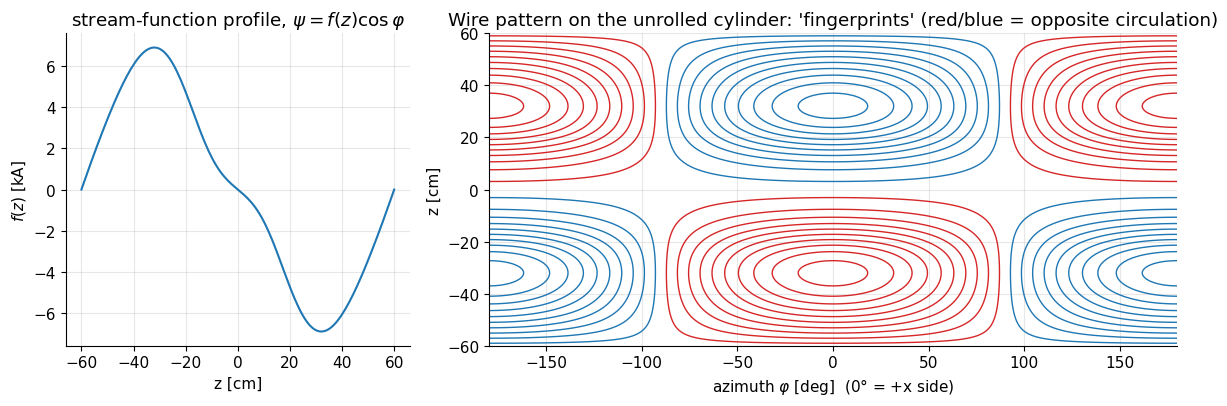

For 40 mT/m with 10 turns per fingerprint: I = 688 A per wire, efficiency eta = 0.058 mT/m/A


In [7]:
G_design = 40e-3                                   # we want 40 mT/m
phi_plot = np.linspace(-np.pi, np.pi, 181)         # centre the plot on the +x side (phi = 0)
z_plot = np.linspace(-ell / 2, ell / 2, 161)
fz = sum(c * np.sin(2 * np.pi * (m + 1) * z_plot / ell) for m, c in enumerate(coef)) * G_design
psi = np.cos(phi_plot)[:, None] * fz[None, :]      # stream function [A] for 40 mT/m
n_turns = 10
psimax = np.abs(psi).max()
levels = (np.arange(n_turns) + 0.5) / n_turns * psimax
I_wire = psimax / n_turns                          # current per wire [A]

fig, ax = plt.subplots(1, 2, figsize=(12, 4.2), gridspec_kw={"width_ratios": [1, 2]})
ax[0].plot(z_plot * 100, fz / 1e3)
ax[0].set(xlabel="z [cm]", ylabel=r"$f(z)$ [kA]", title=r"stream-function profile, $\psi=f(z)\cos\varphi$")
cs = ax[1].contour(np.degrees(phi_plot), z_plot * 100, psi.T, levels=np.concatenate([-levels[::-1], levels]),
                   colors=["C0"] * n_turns + ["C3"] * n_turns, linewidths=1)
ax[1].set(xlabel=r"azimuth $\varphi$ [deg]  (0° = +x side)", ylabel="z [cm]",
          title="Wire pattern on the unrolled cylinder: 'fingerprints' (red/blue = opposite circulation)")
plt.tight_layout(); plt.show()
print(f"For {G_design*1e3:.0f} mT/m with {n_turns} turns per fingerprint: I = {I_wire:.0f} A per wire, "
      f"efficiency eta = {G_design/I_wire*1e3:.3f} mT/m/A")

These concentric, slightly squashed loops are the famous **fingerprint** windings you see in photos of gradient coils (and the closed loops near $\varphi=\pm180°$ are their partners on the $-x$ side). Notice there are no separate "return arcs" far away as in the Golay coil — the regularized optimum makes the coil compact and efficient.

To close the loop, let us take the actual contour lines as wires and compute their field with Biot–Savart (no continuous-current approximation any more):

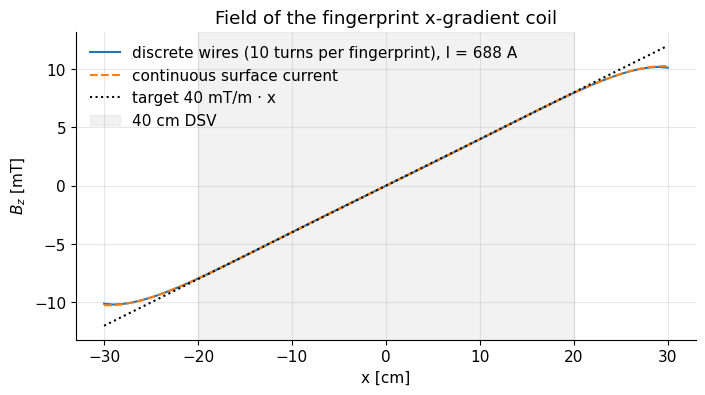

gradient at the centre from the discrete wires: 39.5 mT/m (target 40)


In [8]:
wires = []
for lev_i, path in enumerate(cs.get_paths()):
    for poly in path.to_polygons(closed_only=False):
        if len(poly) < 10:
            continue
        ph, zz = np.radians(poly[:, 0]), poly[:, 1] / 100
        sign = 1.0                          # current direction is given by the orientation of the contour
        wires.append((np.stack([a_c * np.cos(ph), a_c * np.sin(ph), zz], -1), sign))
xx = np.linspace(-0.3, 0.3, 61)
pts_line = np.stack([xx, 0 * xx, 0 * xx], -1)
Bz_wires = sum(wire_field(pts_line, p, I_wire) for p, s in wires)[:, 2]
G_meas = np.gradient(Bz_wires, xx)[30]
if G_meas < 0:          # matplotlib's contour orientation convention decides the sign; fix it once
    Bz_wires, G_meas = -Bz_wires, -G_meas
Bz_cont = surface_Bz(pts_line, coef * G_design)
plt.plot(xx * 100, Bz_wires * 1e3, label=f"discrete wires ({n_turns} turns per fingerprint), I = {I_wire:.0f} A")
plt.plot(xx * 100, Bz_cont * 1e3, "--", label="continuous surface current")
plt.plot(xx * 100, G_design * xx * 1e3, "k:", label="target 40 mT/m · x")
plt.axvspan(-20, 20, color="gray", alpha=0.1, label="40 cm DSV")
plt.xlabel("x [cm]"); plt.ylabel(r"$B_z$ [mT]"); plt.legend(); plt.title("Field of the fingerprint x-gradient coil")
plt.show()
print(f"gradient at the centre from the discrete wires: {G_meas*1e3:.1f} mT/m (target {G_design*1e3:.0f})")

The discrete wires reproduce the design: linear inside the DSV (shaded), bending over outside it — the price of a compact, low-power coil. Gradient non-linearity outside the DSV causes image distortion (Section 8).

> **🔧 Engineering reality:** Real coils are designed with far more constraints than this toy: minimum inductance (fast switching), torque and force balance in $B_0$, active shielding (Section 7), wire spacing and cooling channels, peripheral-nerve-stimulation limits, and all three axes nested in a few centimetres of radial space between the magnet bore (~90 cm) and the patient bore (60–70 cm). The x and y coils sit at slightly different radii, so they never have identical performance.

## 3. The coil as an electrical load: efficiency, inductance, resistance

From the amplifier's point of view a gradient coil is simply an inductor $L$ in series with a resistor $R_{coil}$, characterized by three numbers:

| Quantity | Definition | Typical whole-body value |
|---|---|---|
| efficiency $\eta$ | $G = \eta\,I_c$ | 0.05–0.15 mT/m/A |
| inductance $L$ | stored energy $E_{mag}=\tfrac12 L I_c^2$ | 0.3–1.5 mH |
| resistance $R_{coil}$ | heat $P=I_c^2R_{coil}$ | 0.05–0.2 Ω |

**Scaling with the number of turns $N_t$** (same winding radius and pattern):

- $\eta\propto N_t$ — each turn adds the same field;
- $L\propto N_t^2$ — the field is $N_t$ times larger *and* it links $N_t$ turns;
- $R_{coil}\propto N_t^2$ if the copper must fit in the same space (longer *and* thinner wire).

So the combination

$$\frac{\eta^2}{L}$$

In words: the square of the efficiency divided by the inductance does not depend on how many turns you use — it measures how good the *geometry* is.

is the standard **figure of merit** of a gradient coil. **Scaling with radius $a$** (fixed $N_t$): $\eta\propto 1/a^2$ (Maxwell formula) and $L\propto a$, so $\eta^2/L\propto 1/a^5$. Halving the coil radius improves the figure of merit 32-fold — the reason head-only gradient coils reach 200 mT/m and 500+ T/m/s.

> **📐 Math note:** Energy stored in a field occupying volume $V$ is $E_{mag}=\int\frac{|\vec B|^2}{2\mu_0}dV$. A coil "pays" for the field everywhere — inside the patient but also in the region between the windings and in the fringe outside. Compact coils (small $a$, short length) fill less volume with field and therefore need less energy for the same $G$ at the centre.

In [9]:
# Illustrative whole-body gradient axis (realistic orders of magnitude, not a specific product)
eta = 0.1e-3 / 1.0        # efficiency [T/m per A]  (0.1 mT/m/A)
L = 1.0e-3                # inductance [H]
Rc = 0.1                  # resistance [Ohm]
Imax, Vmax = 800.0, 2000.0  # amplifier limits [A], [V]

Gmax = eta * Imax
Emag = 0.5 * L * Imax**2
print(f"G_max = eta*I_max = {Gmax*1e3:.0f} mT/m")
print(f"stored magnetic energy at I_max: {Emag:.0f} J   (it must be put in and taken out in each ramp)")
print(f"L/R time constant: {L/Rc*1e3:.0f} ms  (vs. ramp times of ~0.2 ms!)")

G_max = eta*I_max = 80 mT/m
stored magnetic energy at I_max: 320 J   (it must be put in and taken out in each ramp)
L/R time constant: 10 ms  (vs. ramp times of ~0.2 ms!)


## 4. The amplifier: why the slew rate is limited by voltage

The voltage across an inductor in series with a resistor is

$$V(t) = L\,\frac{dI_c}{dt} + R_{coil}\,I_c(t).$$

In words: the amplifier must supply a voltage proportional to how *fast* the current changes (the inductive part, Faraday's law of induction — the coil "fights back" against changes) plus a voltage proportional to the current itself (Ohm's law).

where $V$ [V] is the amplifier voltage, $L$ [H] the inductance, $I_c$ [A] the current, $R_{coil}$ [Ω] the resistance. With $G=\eta I_c$, the slew rate is $SR=dG/dt=\eta\,dI_c/dt$; solving for it and using $|V|\le V_{max}$:

$$SR_{max}(I_c) = \frac{\eta\,\big(V_{max}-R_{coil}|I_c|\big)}{L}\ \approx\ \frac{\eta V_{max}}{L}.$$

In words: the fastest possible gradient change is set by the amplifier voltage divided by the inductance (times efficiency); at high current a little of the voltage is "used up" by the resistance, so slewing slows down slightly.

> **🔁 Refresher:** If you apply a *constant* voltage $V$ to the coil, $L\,dI_c/dt=V-R_{coil}I_c$ is a first-order linear ODE with solution $I_c(t)=\frac{V}{R_{coil}}\big(1-e^{-t R_{coil}/L}\big)$ — an exponential approach with time constant $L/R_{coil}$ (see [ODE refresher](../refreshers/RM1_ODEs_for_MRI.ipynb)). Here $L/R_{coil}=10$ ms and the final current $V/R_{coil}=20$ kA is absurdly large: the amplifier uses this "over-drive" (forcing) to ramp in 0.2 ms, then throttles back to the few volts needed to *hold* the current.

In [10]:
SRmax0 = eta * Vmax / L
SRmax_at_Imax = eta * (Vmax - Rc * Imax) / L
print(f"SR_max (low current)   = {SRmax0:.0f} T/m/s")
print(f"SR_max (at I_max)      = {SRmax_at_Imax:.0f} T/m/s")
print(f"rise time 0 -> G_max   = {Gmax/SRmax0*1e3:.2f} ms")
print(f"voltage just to HOLD I_max: {Rc*Imax:.0f} V  (vs {Vmax:.0f} V available for ramping)")

SR_max (low current)   = 200 T/m/s
SR_max (at I_max)      = 192 T/m/s
rise time 0 -> G_max   = 0.40 ms
voltage just to HOLD I_max: 80 V  (vs 2000 V available for ramping)


**The fixed-amplifier trade-off.** With a given amplifier ($V_{max}$, $I_{max}$), the designer still chooses the number of turns: $G_{max}=\eta I_{max}\propto N_t$ while $SR_{max}=\eta V_{max}/L\propto 1/N_t$. Their product

$$G_{max}\cdot SR_{max} = \frac{\eta^2}{L}\,V_{max}I_{max}$$

In words: for a given coil geometry, strength times speed is fixed by the amplifier's peak power ($V_{max}I_{max}$) — more turns buy strength at the cost of speed.

where $V_{max}I_{max}$ [W] is the amplifier's peak "volt-ampere" rating (here 1.6 MVA!). Vendors exploit this: some scanners offer a "strong" and a "fast" gradient mode on the same hardware by switching amplifier configurations.

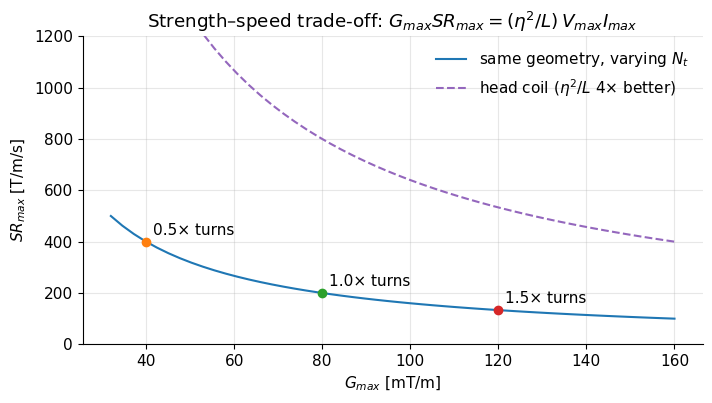

In [11]:
fom = eta**2 / L                              # figure of merit, constant for this geometry
Nscale = np.linspace(0.4, 2.0, 50)            # turns relative to the design above
G_N = (eta * Nscale) * Imax
SR_N = (eta * Nscale) * Vmax / (L * Nscale**2)
plt.plot(G_N * 1e3, SR_N, label=r"same geometry, varying $N_t$")
for s in (0.5, 1.0, 1.5):
    plt.plot(eta * s * Imax * 1e3, eta * s * Vmax / (L * s**2), "o")
    plt.annotate(f"{s:.1f}× turns", (eta * s * Imax * 1e3, eta * s * Vmax / (L * s**2)), textcoords="offset points", xytext=(5, 5))
plt.plot(G_N * 1e3, 4 * SR_N, "--", label=r"head coil ($\eta^2/L$ 4× better)")
plt.xlabel(r"$G_{max}$ [mT/m]"); plt.ylabel(r"$SR_{max}$ [T/m/s]"); plt.ylim(0, 1200)
plt.title(r"Strength–speed trade-off: $G_{max}SR_{max}=(\eta^2/L)\,V_{max}I_{max}$"); plt.legend(); plt.show()

Each curve is a hyperbola: more turns move you to the right (stronger) and down (slower). Only a better geometry ($\eta^2/L$) or a bigger amplifier moves the whole curve up.

**What voltage does a waveform need?** Given a desired gradient waveform we can compute $V(t)=\frac{L}{\eta}\frac{dG}{dt}+\frac{R_{coil}}{\eta}G$ and check it against $V_{max}$.

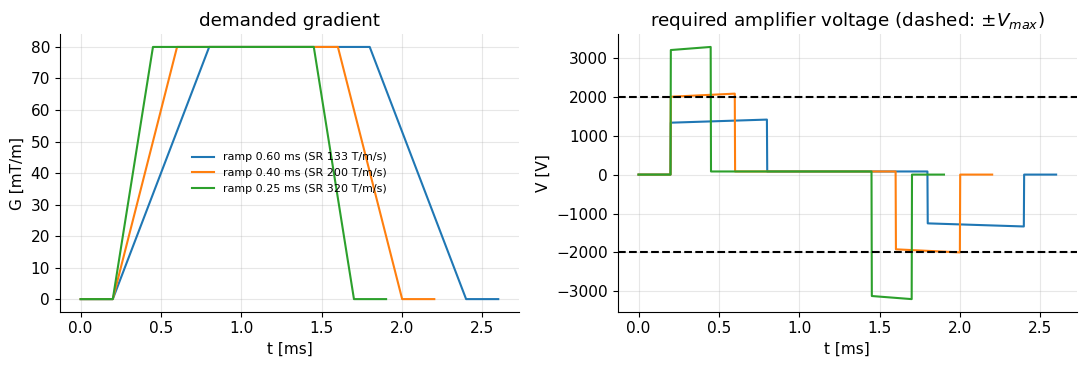

In [12]:
dt = 1e-6
def trapezoid(G, t_ramp, t_flat, dt=dt, pad=0.2e-3):
    """Sampled trapezoid [T/m]: ramp up, flat top, ramp down, with zero padding on both sides."""
    up = np.arange(0, t_ramp, dt) / t_ramp * G
    wave = np.concatenate([np.zeros(int(pad / dt)), up, np.full(int(t_flat / dt), G), up[::-1], np.zeros(int(pad / dt))])
    return np.arange(len(wave)) * dt, wave

fig, ax = plt.subplots(1, 2, figsize=(11, 3.8))
for t_ramp in (0.6e-3, 0.4e-3, 0.25e-3):
    t, g = trapezoid(Gmax, t_ramp, 1e-3)
    V = L / eta * np.gradient(g, dt) + Rc / eta * g
    ax[0].plot(t * 1e3, g * 1e3, label=f"ramp {t_ramp*1e3:.2f} ms (SR {Gmax/t_ramp:.0f} T/m/s)")
    ax[1].plot(t * 1e3, V, label=f"ramp {t_ramp*1e3:.2f} ms")
ax[1].axhline(Vmax, color="k", ls="--"); ax[1].axhline(-Vmax, color="k", ls="--")
ax[0].set(xlabel="t [ms]", ylabel="G [mT/m]", title="demanded gradient"); ax[0].legend(fontsize=8)
ax[1].set(xlabel="t [ms]", ylabel="V [V]", title=r"required amplifier voltage (dashed: $\pm V_{max}$)")
plt.tight_layout(); plt.show()

During the ramps the voltage jumps to $\pm L\,SR/\eta$; on the flat top only the small resistive voltage ($R_{coil}I_c$ = 80 V) remains. The 0.25 ms ramp (320 T/m/s) would need 3.2 kV — beyond this amplifier, so the sequence software must never request it.

> **🔧 Engineering reality:** Gradient amplifiers are switch-mode power electronics (stacked H-bridges switching IGBT or SiC transistors at tens of kHz, combined to ~1–2.5 kV and 500–1000 A per axis), with a fast current-feedback loop that makes the coil current follow the demand within a few µs. They must also be extremely *quiet*: current ripple or noise of 1 part in 10⁵ of full scale is visible as image artifacts. The energy put into the coil at each ramp ($\tfrac12LI_c^2$ ≈ 300 J) is recovered into capacitor banks on the ramp-down.

## 5. Gradient waveforms: minimum-time trapezoids and triangles

A gradient lobe is specified by its **area** $A=\int G(t)\,dt$ [T·s/m], because the area moves you in k-space: $\Delta k=\bar\gamma A$ [m⁻¹] ([K-space](../pass2_deep_dive/F2_K-space.ipynb)). Given $G_{max}$ and $SR_{max}$, the fastest lobe with area $A$ is:

- a **triangle** if the area is small: ramp up at full slew rate, immediately ramp down. Peak $G_p=\sqrt{A\,SR}$, duration $T=2\sqrt{A/SR}$;
- a **trapezoid** if $A > G_{max}^2/SR$ (the triangle would exceed $G_{max}$): ramps $t_r=G_{max}/SR$, flat top $t_{flat}=A/G_{max}-t_r$, total

$$T_{trap} = \frac{A}{G_{max}}+\frac{G_{max}}{SR}.$$

In words: total duration = time to accumulate the area at full strength + one extra ramp time (the two half-filled ramps together count as one ramp at full height).

where $A$ [T s/m] is the required area, $G_{max}$ [T/m], $SR$ [T/m/s], $t_r$ [s] the ramp time.

<details><summary><b>📐 Derivation (optional)</b></summary>

A symmetric trapezoid with ramp time $t_r$ and flat top $t_{flat}$ at height $G$ has area $A=G\,t_{flat}+2\cdot\tfrac12 G t_r = G(t_{flat}+t_r)$, and total duration $T=t_{flat}+2t_r$. With $t_r=G/SR$: $T = A/G + G/SR$. Minimizing over $G$: $dT/dG=-A/G^2+1/SR=0 \Rightarrow G=\sqrt{A\,SR}$. If this optimum exceeds $G_{max}$, the best feasible choice is $G=G_{max}$ (because $T$ decreases with $G$ below the optimum). If it does not, $t_{flat}=A/G-t_r=\sqrt{A/SR}-\sqrt{A/SR}=0$: a triangle of duration $2\sqrt{A/SR}$.

</details>

k_max = 500 1/m  ->  area = 11.74 mT*ms/m
entry level 1.5 T (30 mT/m, 100 T/m/s)        trapezoid duration 0.691 ms;  numeric area check 1.000
clinical 3 T (80 mT/m, 200 T/m/s)             triangle  duration 0.485 ms;  numeric area check 1.000
head-only high-perf. (200 mT/m, 900 T/m/s)    triangle  duration 0.228 ms;  numeric area check 1.000


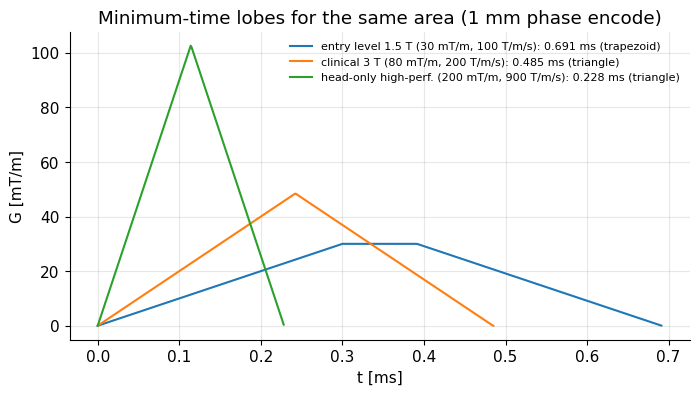

In [13]:
def min_time_lobe(area, Gmax, SR, dt=1e-6):
    """Minimum-time gradient lobe (triangle or trapezoid) for a given area [T s/m].
    Returns (t [s], G [T/m]) sampled at dt, the duration and the shape name."""
    area_sign, area = np.sign(area), abs(area)
    if area <= Gmax**2 / SR:                       # triangle is enough
        Gp, t_r, t_flat, shape = np.sqrt(area * SR), np.sqrt(area / SR), 0.0, "triangle"
    else:
        Gp, t_r, shape = Gmax, Gmax / SR, "trapezoid"
        t_flat = area / Gmax - t_r
    T = 2 * t_r + t_flat
    t = np.arange(0, T + dt / 2, dt)
    g = np.minimum.reduce([np.full_like(t, Gp), t / t_r * Gp, (T - t) / t_r * Gp])
    return t, area_sign * np.clip(g, 0, None), T, shape

# Example: phase-encode lobe for 1 mm resolution: k_max = 1/(2 delta)
delta = 1e-3
k_max = 1 / (2 * delta)                       # [1/m]
A_pe = k_max / mt.GAMMA_BAR                    # [T s/m]
print(f"k_max = {k_max:.0f} 1/m  ->  area = {A_pe*1e6:.2f} mT*ms/m")
systems = {"entry level 1.5 T (30 mT/m, 100 T/m/s)": (30e-3, 100),
           "clinical 3 T (80 mT/m, 200 T/m/s)": (80e-3, 200),
           "head-only high-perf. (200 mT/m, 900 T/m/s)": (200e-3, 900)}
for name, (Gm, sr) in systems.items():
    t, g, T, shape = min_time_lobe(A_pe, Gm, sr)
    plt.plot(t * 1e3, g * 1e3, label=f"{name}: {T*1e3:.3f} ms ({shape})")
    print(f"{name:45s} {shape:9s} duration {T*1e3:.3f} ms;  numeric area check {np.sum(g)*1e-6/A_pe:.3f}")
plt.xlabel("t [ms]"); plt.ylabel("G [mT/m]"); plt.title("Minimum-time lobes for the same area (1 mm phase encode)")
plt.legend(fontsize=8); plt.show()

All three lobes have the same area (same k-space step). The weaker system needs a long trapezoid; the head-only system finishes in a fraction of the time with a lobe that does not even reach its $G_{max}$ (slew-rate limited).

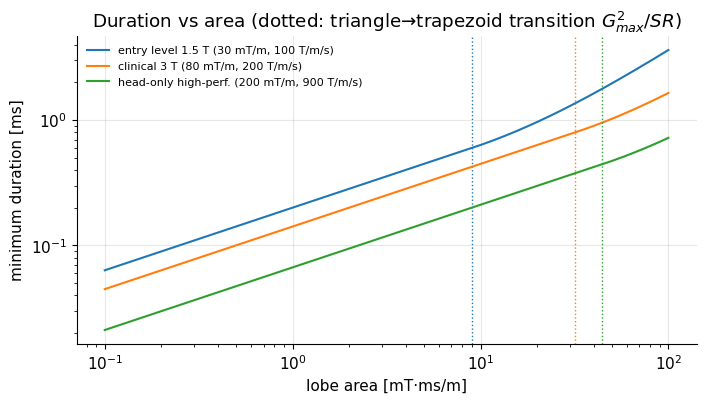

In [14]:
areas = np.logspace(-7, -4, 200)               # [T s/m]
for name, (Gm, sr) in systems.items():
    T = [min_time_lobe(A, Gm, sr)[2] for A in areas]
    plt.loglog(areas * 1e6, np.array(T) * 1e3, label=name)
    plt.axvline(Gm**2 / sr * 1e6, color=plt.gca().lines[-1].get_color(), ls=":", lw=1)
plt.xlabel("lobe area [mT·ms/m]"); plt.ylabel("minimum duration [ms]")
plt.title("Duration vs area (dotted: triangle→trapezoid transition $G_{max}^2/SR$)"); plt.legend(fontsize=8); plt.show()

Small areas (left) are **slew-rate limited** — duration grows as $\sqrt{A}$ (slope ½); large areas (right) are **amplitude limited** — duration grows linearly. Diffusion encoding (huge areas) benefits from $G_{max}$; EPI blips and short TE benefit from $SR$.

**EPI echo spacing.** In an EPI readout each line is one trapezoid whose flat top covers $k$ from $-k_{max}$ to $+k_{max}$. With ramp sampling ignored, the readout area is $A_{ro}=N_{read}/(\bar\gamma FOV)$ and the echo spacing is roughly the duration of one lobe. The amplitude is also capped by the receiver bandwidth, but let us look at the gradient limit alone:

In [15]:
FOV, Nread = 0.24, 128
A_ro = Nread / (mt.GAMMA_BAR * FOV)       # area for 2*k_max  [T s/m]
for name, (Gm, sr) in systems.items():
    T = min_time_lobe(A_ro, Gm, sr)[2]
    print(f"{name:45s} minimum echo spacing ≈ {T*1e3:.2f} ms")

entry level 1.5 T (30 mT/m, 100 T/m/s)        minimum echo spacing ≈ 0.72 ms
clinical 3 T (80 mT/m, 200 T/m/s)             minimum echo spacing ≈ 0.50 ms
head-only high-perf. (200 mT/m, 900 T/m/s)    minimum echo spacing ≈ 0.24 ms


Shorter echo spacing means less distortion and blurring in EPI ([Fast Imaging](../pass2_deep_dive/H2_Fast_Imaging_Pulse_Sequences.ipynb), [Artifacts](../pass2_deep_dive/I2_Artifacts.ipynb)). In practice, however, whole-body EPI rarely runs at the hardware limit: nerve stimulation (Section 10) is usually hit first.

## 6. Duty cycle, heating and cooling

The coil turns electrical power into heat at the rate $P=I_c^2R_{coil}$. Over a sequence what counts is the **root-mean-square** current,

$$I_{rms}=\sqrt{\frac1T\int_0^T I_c(t)^2\,dt},\qquad P = I_{rms}^2R_{coil}.$$

In words: because heating goes with the *square* of the current, long strong gradient lobes (diffusion, EPI) heat much more than short weak ones; the average power is the mean of $I_c^2$, not the square of the mean.

where $T$ [s] is the sequence repetition period. The **duty cycle** is often quoted as the fraction of time the gradient may run at full amplitude: duty $=I_{rms}^2/I_{max}^2$.

I_rms = 268 A, duty = 11 %, heat per axis P = 7.2 kW
if all 3 axes worked this hard: cooling water warms by 10.3 K at 30 L/min  (dT = P/(m_dot c_p))


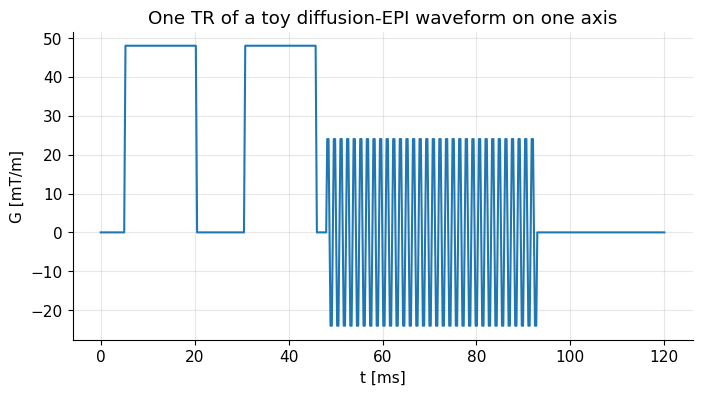

In [16]:
# A diffusion-weighted EPI-like TR (very rough): two big diffusion lobes + an EPI train, repeated every 120 ms
TR = 0.12
t, g1 = trapezoid(0.6 * Gmax, 0.25e-3, 15e-3, pad=0)      # diffusion lobes at 48 mT/m
t, ro = trapezoid(0.3 * Gmax, 0.2e-3, 0.3e-3, pad=0)       # EPI readout at 24 mT/m
epi = np.concatenate([ro * (-1) ** n for n in range(64)])
wave = np.concatenate([np.zeros(5000), g1, np.zeros(10000), g1, np.zeros(2000), epi])
wave = np.concatenate([wave, np.zeros(int(TR / dt) - len(wave))])
I = wave / eta
Irms = np.sqrt(np.mean(I**2))
P = Irms**2 * Rc
print(f"I_rms = {Irms:.0f} A, duty = {Irms**2/Imax**2*100:.0f} %, heat per axis P = {P/1e3:.1f} kW")
flow = 30 / 60                                    # cooling water 30 L/min -> kg/s (1 L of water ≈ 1 kg)
print(f"if all 3 axes worked this hard: cooling water warms by {3*P/(flow*4186):.1f} K at 30 L/min  (dT = P/(m_dot c_p))")
plt.plot(np.arange(len(wave)) * dt * 1e3, wave * 1e3); plt.xlabel("t [ms]"); plt.ylabel("G [mT/m]")
plt.title("One TR of a toy diffusion-EPI waveform on one axis"); plt.show()

Kilowatts of heat in a few hundred kg of copper and epoxy: a gradient coil is **water cooled** (hollow conductors or cooling tubes between layers), and the heat also warms the passive iron shims of the magnet, drifting $B_0$ during long scans ([B3](../pass2_deep_dive/B3_Main_Magnet_Engineering.ipynb)).

A simple **lumped thermal model** shows why scanners limit gradient-heavy protocols: $C_{th}\,dT_{coil}/dt = P - (T_{coil}-T_{water})/R_{th}$, a first-order ODE with time constant $R_{th}C_{th}$ ([ODE refresher](../refreshers/RM1_ODEs_for_MRI.ipynb)).

P = 15 kW reaches 70 °C after 18 min


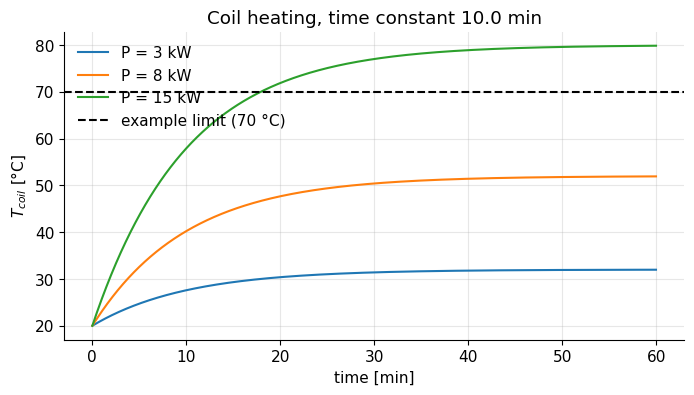

In [17]:
C_th, R_th = 1.5e5, 4e-3      # thermal capacity [J/K], thermal resistance [K/W]  (illustrative)
T_w = 20.0                    # cooling water [deg C]
tt = np.arange(0, 3600, 1.0)
for Pw in (3e3, 8e3, 15e3):
    Tc = T_w + Pw * R_th * (1 - np.exp(-tt / (R_th * C_th)))   # exact solution of the ODE
    plt.plot(tt / 60, Tc, label=f"P = {Pw/1e3:.0f} kW")
    if T_w + Pw * R_th > 70:
        print(f"P = {Pw/1e3:.0f} kW reaches 70 °C after {-R_th*C_th*np.log(1-(70-T_w)/(Pw*R_th))/60:.0f} min")
plt.axhline(70, color="k", ls="--", label="example limit (70 °C)")
plt.xlabel("time [min]"); plt.ylabel(r"$T_{coil}$ [°C]"); plt.legend(); plt.title(f"Coil heating, time constant {R_th*C_th/60:.1f} min")
plt.show()

At high power the coil reaches the (illustrative) temperature limit within a typical exam duration (see the printed time), so the scanner's gradient-heating model would throttle the protocol (longer TR, fewer slices) — that is the "gradient duty cycle exceeded" message on the console.

> **🔧 Engineering reality:** At kHz frequencies the *effective* resistance rises above the DC value (skin and proximity effects in the conductors, eddy currents in nearby metal), so heating depends on the waveform spectrum, not only on $I_{rms}$. Gradient amplifiers also have their own thermal limits.

## 7. Eddy currents, pre-emphasis and active shielding

### 7.1 Where eddy currents come from

A changing gradient field passes through the conducting structures around the coil — above all the metal cylinders of the magnet's cryostat (warm bore, thermal shields, helium vessel). By Faraday's law, a changing magnetic flux induces an electric field, which drives **eddy currents** in any conductor. By **Lenz's rule** these currents flow in the direction that *opposes* the change. So right after a gradient ramp, the eddy currents produce a field that subtracts from the intended gradient; it then decays as the currents die out in the resistive metal (time constants from ~0.1 ms in thin structures to ~100 ms+ in the cold, highly conductive helium vessel).

> **🔁 Refresher:** Faraday's law and Lenz's rule: [Induction & RF](../refreshers/RP2_Induction_and_RF.ipynb).

**Model.** Each conducting structure behaves like an RL circuit coupled to the coil. Its response to a gradient *step* of height $G_0$ is a decaying exponential, so the total response to a step is

$$G_{actual}(t)=G_0\Big(1-\sum_n\alpha_n e^{-t/\tau_n}\Big),\quad t\ge0,$$

In words: right after the step the gradient is too small by the fraction $\sum_n\alpha_n$, and the deficit decays away with time constants $\tau_n$.

where $\alpha_n$ [–] is the relative amplitude and $\tau_n$ [s] the time constant of term $n$. Because the system is linear and time-invariant, an arbitrary waveform is a sum of small steps $dG$, and each step creates its own decaying eddy field. Summing them gives a convolution:

$$G_{actual}(t) = G_{in}(t) - \sum_n \alpha_n\int_{-\infty}^{t}\frac{dG_{in}}{d\tau}(\tau)\,e^{-(t-\tau)/\tau_n}\,d\tau .$$

In words: the actual gradient is the input minus, for each eddy term, a "memory" of all past changes of the gradient that fades with time constant $\tau_n$. Ramps up cause a deficit; ramps down cause an overshoot of the opposite sign (a tail).

where $G_{in}$ is the waveform the amplifier produces and $\tau$ the integration variable (time of each past change). This is a convolution of $dG_{in}/dt$ with the kernel $h_e(t)=\sum_n\alpha_ne^{-t/\tau_n}$ for $t\ge0$ ([convolution refresher](../refreshers/RM4_Fourier_Properties.ipynb)).

Numerically each exponential term is a first-order recursive filter: $y_n[j]=e^{-\Delta t/\tau_n}\,y_n[j-1]+\alpha_n\,(G[j]-G[j-1])$.

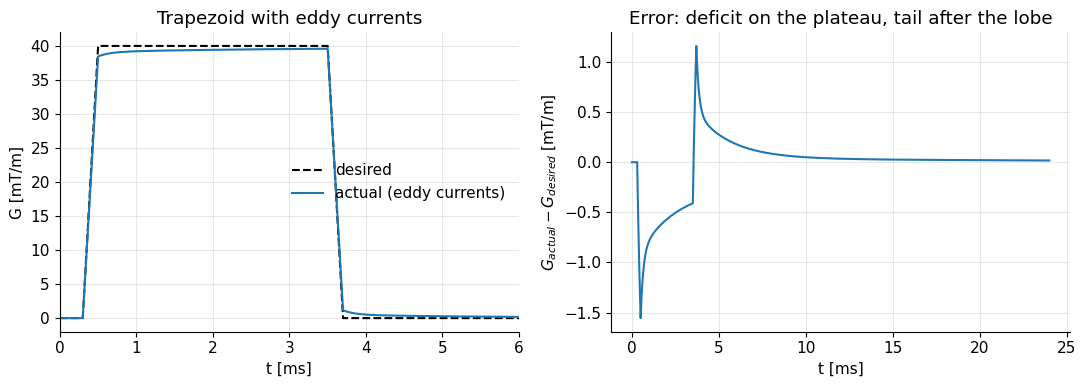

residual area after the lobe (t > 4 ms): 1.320 mT*ms/m = k-space error 56.2 1/m


In [18]:
from scipy.signal import lfilter

alpha = np.array([0.03, 0.015, 0.008])         # eddy amplitudes (uncompensated, illustrative)
tau_e = np.array([0.15e-3, 2e-3, 25e-3])       # eddy time constants [s]

def apply_eddy(g, alpha=alpha, tau=tau_e, dt=dt):
    """Actual gradient = input - sum_n alpha_n * (exp(-t/tau_n) convolved with dG/dt)."""
    dg = np.diff(g, prepend=0.0)
    eddy = sum(lfilter([a_n], [1, -np.exp(-dt / t_n)], dg) for a_n, t_n in zip(alpha, tau))
    return g - eddy

t, g_des = trapezoid(40e-3, 0.2e-3, 3e-3, pad=0.3e-3)
t = np.arange(len(g_des) + 20000) * dt
g_des = np.concatenate([g_des, np.zeros(20000)])          # look 20 ms past the lobe
g_act = apply_eddy(g_des)

fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ax[0].plot(t * 1e3, g_des * 1e3, "k--", label="desired"); ax[0].plot(t * 1e3, g_act * 1e3, label="actual (eddy currents)")
ax[0].set(xlabel="t [ms]", ylabel="G [mT/m]", xlim=(0, 6), title="Trapezoid with eddy currents"); ax[0].legend()
ax[1].plot(t * 1e3, (g_act - g_des) * 1e3)
ax[1].set(xlabel="t [ms]", ylabel=r"$G_{actual}-G_{desired}$ [mT/m]", title="Error: deficit on the plateau, tail after the lobe")
plt.tight_layout(); plt.show()
print(f"residual area after the lobe (t > 4 ms): {np.sum((g_act-g_des)[t>4e-3])*dt*1e6:.3f} mT*ms/m "
      f"= k-space error {mt.GAMMA_BAR*np.sum((g_act-g_des)[t>4e-3])*dt:.1f} 1/m")

The plateau starts ~5 % low and recovers; after the lobe ends, the eddy currents keep producing a negative "tail" for tens of ms. Both shift the k-space trajectory: misplaced echoes, EPI Nyquist ghosts, distorted diffusion images, mis-refocused spin echoes.

### 7.2 Pre-emphasis: pre-distorting the input

Because the distortion is linear and known (it is measured at installation), we can invert it: drive the amplifier with an over-shooting waveform $G_{in}$ chosen so that $G_{actual}=G_{desired}$. Solving the recursion above for $G_{in}[j]$ step by step gives the exact inverse:

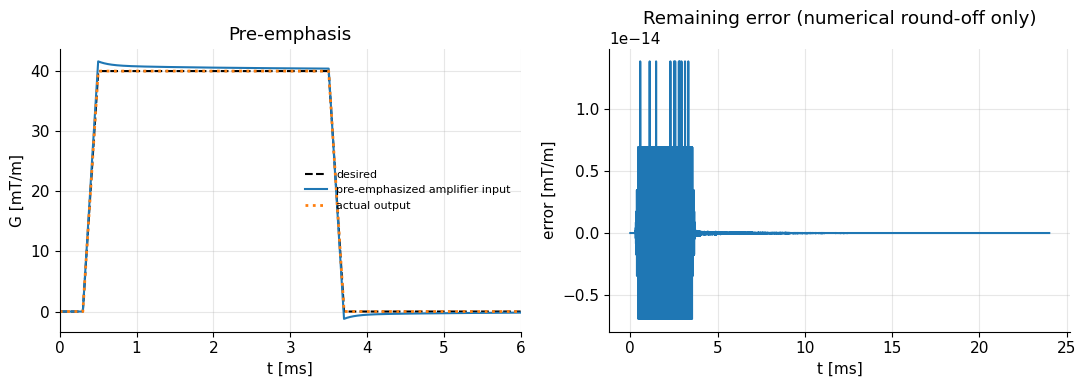

peak of the pre-emphasized input: 41.6 mT/m (desired 40) -> amplifier needs headroom


In [19]:
def pre_emphasize(g_des, alpha=alpha, tau=tau_e, dt=dt):
    """Exact inverse of apply_eddy: find g_in such that apply_eddy(g_in) == g_des (sample by sample)."""
    a_dec = np.exp(-dt / tau)
    y = np.zeros(len(alpha)); g_in = np.zeros_like(g_des); prev = 0.0
    for j, gd in enumerate(g_des):
        # g_des = g_in - sum_n [a_n y_n + alpha_n (g_in - prev)]  ->  solve for g_in
        g_in[j] = (gd + np.sum(a_dec * y) - np.sum(alpha) * prev) / (1 - np.sum(alpha))
        y = a_dec * y + alpha * (g_in[j] - prev)
        prev = g_in[j]
    return g_in

g_in = pre_emphasize(g_des)
g_out = apply_eddy(g_in)
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ax[0].plot(t * 1e3, g_des * 1e3, "k--", label="desired")
ax[0].plot(t * 1e3, g_in * 1e3, label="pre-emphasized amplifier input")
ax[0].plot(t * 1e3, g_out * 1e3, ":", lw=2, label="actual output")
ax[0].set(xlabel="t [ms]", ylabel="G [mT/m]", xlim=(0, 6), title="Pre-emphasis"); ax[0].legend(fontsize=8)
ax[1].plot(t * 1e3, (g_out - g_des) * 1e3)
ax[1].set(xlabel="t [ms]", ylabel="error [mT/m]", title="Remaining error (numerical round-off only)")
plt.tight_layout(); plt.show()
print(f"peak of the pre-emphasized input: {g_in.max()*1e3:.1f} mT/m (desired 40) -> amplifier needs headroom")

The pre-emphasized input overshoots at each edge (it "kicks" harder to compensate the opposing eddy field) and the output now matches the desired trapezoid. The amplifier must reserve some current and voltage headroom for these kicks.

In real scanners pre-emphasis is implemented as a filter of the same form, $G_{in}=G_{des}+\sum_n\beta_n\,(e^{-t/\tau_n'}*\frac{dG_{des}}{dt})$, with a handful of amplitudes $\beta_n$ and time constants $\tau_n'$ tuned at installation.

<details><summary><b>📐 Derivation (optional): pre-emphasis for one exponential</b></summary>

Using the Laplace transform (the Fourier transform's sibling; for sinusoids at frequency $f$ just set $s=i2\pi f$), differentiation becomes multiplication by $s$, convolution becomes multiplication, and $e^{-t/\tau_1}\to\tau_1/(1+s\tau_1)$. The eddy system is therefore

$$H(s)=\frac{G_{actual}}{G_{in}}=1-\alpha_1\frac{s\tau_1}{1+s\tau_1}=\frac{1+s\tau_1(1-\alpha_1)}{1+s\tau_1}.$$

Its inverse is

$$\frac{1}{H(s)}=\frac{1+s\tau_1}{1+s\tau_1(1-\alpha_1)} = 1+\beta_1\frac{s\tau_1'}{1+s\tau_1'},\qquad \tau_1'=\tau_1(1-\alpha_1),\ \ \beta_1=\frac{\alpha_1}{1-\alpha_1}.$$

(Check by multiplying out: $1+\beta_1 s\tau_1'/(1+s\tau_1')=(1+s\tau_1'(1+\beta_1))/(1+s\tau_1')$ and $\tau_1'(1+\beta_1)=\tau_1$.) So the pre-emphasis for one eddy term is *another* exponential term, with slightly larger amplitude and slightly shorter time constant. For several small terms, $\beta_n\approx\alpha_n$, $\tau_n'\approx\tau_n$ is a good first guess that is then refined.

</details>

In [20]:
# check the closed-form single-term-per-component approximation against the exact inverse
beta = alpha / (1 - alpha); tau_p = tau_e * (1 - alpha)
dgd = np.diff(g_des, prepend=0.0)
g_in_approx = g_des + sum(lfilter([b_n], [1, -np.exp(-dt / t_n)], dgd) for b_n, t_n in zip(beta, tau_p))
err_approx = apply_eddy(g_in_approx) - g_des
print(f"max error with approximate (per-term) pre-emphasis: {np.abs(err_approx).max()*1e3:.3f} mT/m "
      f"(uncompensated: {np.abs(g_act-g_des).max()*1e3:.2f} mT/m)")

max error with approximate (per-term) pre-emphasis: 0.039 mT/m (uncompensated: 1.55 mT/m)


The per-term formula already removes ~95 % of the error; the residual comes from the interaction of the terms and is what installation-time tuning removes.

> **🔧 Engineering reality:** Eddy currents have **spatial** structure too: besides the "linear" term that mimics the gradient, a gradient switch produces a spatially *constant* eddy field ("B0 eddy current", a frequency shift of the whole image) and higher-order terms. Scanners measure and compensate the B0 and linear terms (B0 compensation is applied to the frequency synthesizer or the shim coil). Today, the full linear response of the gradient chain is often characterized by a **gradient impulse response function (GIRF)** and used to correct trajectories in the reconstruction (spiral, radial, EPI).

### 7.3 Active shielding

Pre-emphasis fixes the *waveform*, but eddy currents also heat the cryostat (boil-off of helium) and have spatial patterns that cannot be fully compensated. The far better approach, standard since the late 1980s, is to prevent the gradient field from reaching the cryostat in the first place: a second winding (the **shield coil**) at a larger radius carries opposite current, designed so that the combined field **outside** the shield is nearly zero. Let us design a shielded z-gradient: a Maxwell pair at $a=0.30$ m plus 24 shield loops at 0.40 m (spread over ±0.9 m), with currents chosen by least squares to null the field on the cryostat bore at 0.45 m.

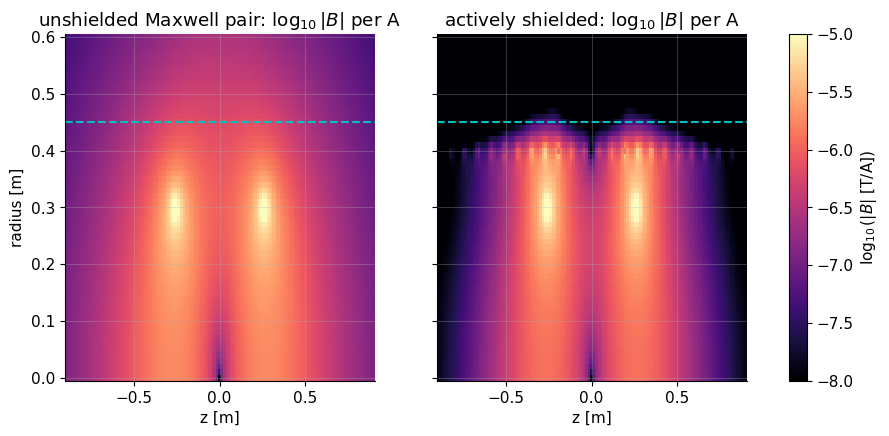

field on cryostat (max |B|): unshielded 0.67 uT/A, shielded 0.056 uT/A
gradient efficiency at the centre: 8.96 -> 6.01 uT/m per A (33 % loss)


In [21]:
a_p, a_s, r_cryo = 0.30, 0.40, 0.45                    # primary, shield, cryostat radii [m]
z_shield = np.linspace(-0.9, 0.9, 24)                  # positions of the shield loops [m]
z_cryo = np.linspace(-0.8, 0.8, 81)
cryo_pts = np.stack([np.full_like(z_cryo, r_cryo), 0 * z_cryo, z_cryo], -1)

def primary_B(p):
    return (mt.loop_coil_field(p, a_p, 1.0, center=(0, 0, np.sqrt(3) / 2 * a_p))
            + mt.loop_coil_field(p, a_p, -1.0, center=(0, 0, -np.sqrt(3) / 2 * a_p)))

# matrix of fields (both B_r=B_x here and B_z) on the cryostat per 1 A in each shield loop
Bs = np.stack([mt.loop_coil_field(cryo_pts, a_s, 1.0, center=(0, 0, zs)) for zs in z_shield], -1)   # (81, 3, 12)
A_sh = np.concatenate([Bs[:, 0, :], Bs[:, 2, :]])
b_sh = -np.concatenate([primary_B(cryo_pts)[:, 0], primary_B(cryo_pts)[:, 2]])
I_shield = np.linalg.lstsq(A_sh, b_sh, rcond=None)[0]

def shielded_B(p):
    return primary_B(p) + sum(I * mt.loop_coil_field(p, a_s, 1.0, center=(0, 0, zs)) for I, zs in zip(I_shield, z_shield))

# compare |B| in the r-z plane
rr, zz = np.meshgrid(np.linspace(0.0, 0.6, 61), np.linspace(-0.9, 0.9, 121))
plane = np.stack([rr, 0 * rr, zz], -1)
B_un, B_sh = np.linalg.norm(primary_B(plane), axis=-1), np.linalg.norm(shielded_B(plane), axis=-1)
fig, ax = plt.subplots(1, 2, figsize=(11, 4.5), sharey=True)
for axi, Bm, title in [(ax[0], B_un, "unshielded Maxwell pair"), (ax[1], B_sh, "actively shielded")]:
    im = axi.pcolormesh(zz, rr, np.log10(Bm + 1e-12), vmin=-8, vmax=-5, shading="auto", cmap="magma")
    axi.axhline(r_cryo, color="c", ls="--"); axi.set(xlabel="z [m]", title=title + r": $\log_{10}|B|$ per A")
ax[0].set_ylabel("radius [m]"); plt.colorbar(im, ax=ax, label=r"$\log_{10}(|B|$ [T/A]$)$"); plt.show()

zc_ax = np.stack([0 * z, 0 * z, z], -1)
G_un = np.gradient(primary_B(zc_ax)[:, 2], z)[len(z) // 2]; G_sh = np.gradient(shielded_B(zc_ax)[:, 2], z)[len(z) // 2]
print(f"field on cryostat (max |B|): unshielded {np.abs(primary_B(cryo_pts)).max()*1e6:.2f} uT/A, "
      f"shielded {np.abs(shielded_B(cryo_pts)).max()*1e6:.3f} uT/A")
print(f"gradient efficiency at the centre: {G_un*1e6:.2f} -> {G_sh*1e6:.2f} uT/m per A ({(1-G_sh/G_un)*100:.0f} % loss)")

The dashed cyan line is the cryostat. With the shield, the field there drops by more than an order of magnitude, while the gradient in the imaging region survives — but with a substantial loss in efficiency (the shield's opposite current also partly cancels the field inside). Shielding therefore costs current, power and inductance, which is why it is designed together with the primary in one optimization (Section 2.3) rather than added afterwards as here.

> **🔧 Engineering reality:** Shielded coils reduce eddy currents by ~100×, leaving ~0.1–1 % residuals that pre-emphasis handles. Shielding also reduces the gradient-induced vibration and heating of the cryostat (helium boil-off).

## 8. Linearity, field of view and geometric distortion

The reconstruction assumes $B_z=B_0+\vec G\cdot\vec r$ everywhere. If the real field deviates, a spin at true position $x$ is encoded as if it were at $x'=B_z^{(x\text{-coil})}(\vec r)/G_x$ — the image is **geometrically distorted**, increasingly towards the edges of a large FOV. Using our fingerprint x-coil (and the same coil rotated by 90° as y-coil, since $B_z^{(y)}(x,y,z)=B_z^{(x)}(y,-x,z)$) we can map where a regular grid ends up in the image.

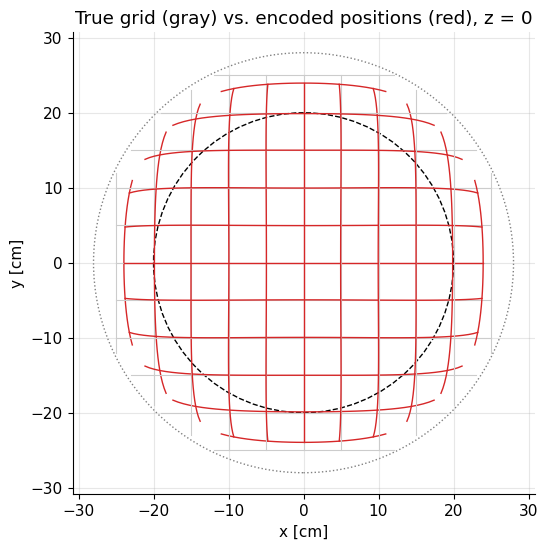

In [22]:
s = np.linspace(-0.25, 0.25, 11)        # grid lines every 5 cm [m]
fine = np.linspace(-0.25, 0.25, 51)
fig, ax = plt.subplots(figsize=(6, 6))
for c0 in s:
    for line in (np.stack([fine, np.full_like(fine, c0), 0 * fine], -1),     # horizontal lines (y = const)
                 np.stack([np.full_like(fine, c0), fine, 0 * fine], -1)):    # vertical lines   (x = const)
        line = line[np.hypot(line[:, 0], line[:, 1]) <= 0.28]            # stay inside a 56 cm patient bore
        x_enc = surface_Bz(line, coef * G_design) / G_design
        y_enc = surface_Bz(np.stack([line[:, 1], -line[:, 0], line[:, 2]], -1), coef * G_design) / G_design
        ax.plot(line[:, 0] * 100, line[:, 1] * 100, color="0.8", lw=0.8)
        ax.plot(x_enc * 100, y_enc * 100, color="C3", lw=1)
ax.add_patch(plt.Circle((0, 0), 20, fill=False, ls="--", color="k"))
ax.add_patch(plt.Circle((0, 0), 28, fill=False, ls=":", color="gray"))
ax.set(xlabel="x [cm]", ylabel="y [cm]", aspect="equal", title="True grid (gray) vs. encoded positions (red), z = 0")
plt.show()

Inside the 40 cm DSV (dashed circle) the red grid nearly coincides with the true grid; outside (up to the dotted 56 cm bore), the gradient falls off and objects are compressed towards the centre ("barrel" distortion) — near the bore edge the error reaches several cm.

> **🔧 Engineering reality:** Vendors characterize each coil's field by spherical-harmonic coefficients and apply **gradient non-linearity (distortion) correction** ("2D/3D distortion correction", "GradWarp") in the reconstruction, see [Artifacts](../pass2_deep_dive/I2_Artifacts.ipynb). It fixes geometry but not the intensity and resolution changes caused by the locally different gradient, nor slice bending (the slice-select gradient is non-linear too). Gradient linearity is specified as a maximum deviation (a few %) over a stated DSV (e.g. 40–50 cm). Shorter, more efficient coils (like head gradients) have a smaller linear region.

## 9. Concomitant fields: what Maxwell adds

We wrote $B_z=B_0+G_xx$ as if the gradient coil only changed $B_z$. But in the current-free imaging region the field must satisfy two of Maxwell's equations,

$$\nabla\cdot\vec B=0,\qquad \nabla\times\vec B=\vec 0 ,$$

In words: field lines never start or end (no "magnetic charges"), and where there are no currents the field has no curl (no whirl).

where $\nabla\cdot\vec B=\partial B_x/\partial x+\partial B_y/\partial y+\partial B_z/\partial z$ (divergence) and $\nabla\times$ is the curl. A field with *only* $B_z=G_xx$ has curl component $\partial B_z/\partial x-\partial B_x/\partial z=G_x\neq0$ — forbidden. The simplest legal fields are

$$\text{x-gradient: }\ \vec B=\begin{bmatrix}G_x z\\0\\B_0+G_x x\end{bmatrix},\qquad \text{z-gradient: }\ \vec B=\begin{bmatrix}-G_z x/2\\-G_z y/2\\B_0+G_z z\end{bmatrix}.$$

In words: every gradient coil necessarily also produces transverse field components, the **concomitant fields** (also called Maxwell terms). They grow with distance from the centre.

The spins precess at $\bar\gamma|\vec B|$. Expanding $|\vec B|=\sqrt{B_z^2+B_x^2+B_y^2}\approx B_z+\frac{B_x^2+B_y^2}{2B_0}$ (valid because $B_0$ dominates):

$$\Delta f_{cc}^{(x)}\approx\bar\gamma\frac{G_x^2z^2}{2B_0},\qquad \Delta f_{cc}^{(z)}\approx\bar\gamma\frac{G_z^2(x^2+y^2)}{8B_0}.$$

In words: the extra precession frequency grows with the *square* of the gradient and the square of the distance from isocenter, and it is *inversely* proportional to $B_0$ — concomitant fields are a low-field and high-gradient problem.

where $\Delta f_{cc}$ [Hz] is the concomitant-field frequency offset, $\bar\gamma$ [Hz/T], $G$ [T/m], positions in m, $B_0$ [T].

<details><summary><b>📐 Check (optional)</b></summary>

x-gradient: $\nabla\cdot\vec B=\partial_x(G_xz)+\partial_z(B_0+G_xx)=0$ ✓; curl $y$-component $\partial_zB_x-\partial_xB_z=G_x-G_x=0$ ✓.
z-gradient: $\nabla\cdot\vec B=-G_z/2-G_z/2+G_z=0$ ✓; curl $x$-component $\partial_yB_z-\partial_zB_y=0$ ✓.
Other choices are possible (e.g. $\vec B=[0,0,B_0+G_xx]+[G_xz,0,0]\cdot$weights) but the transverse terms can never all vanish.

</details>

In [23]:
# verify with Biot-Savart: the Maxwell pair must have a radial field B_x ≈ -G_z x / 2 near the centre
a = 0.30
p = np.array([[0.05, 0, 0], [0.10, 0, 0], [0.15, 0, 0]])
Bp = (mt.loop_coil_field(p, a, 1.0, center=(0, 0, np.sqrt(3) / 2 * a)) + mt.loop_coil_field(p, a, -1.0, center=(0, 0, -np.sqrt(3) / 2 * a)))
Gz1 = 0.641 * mt.MU0 / a**2
print("B_x from Biot-Savart :", np.round(Bp[:, 0] * 1e6, 3), "uT/A")
print("-G_z x / 2 prediction:", np.round(-Gz1 * p[:, 0] / 2 * 1e6, 3), "uT/A")

for B0_ in (0.55, 1.5, 3.0, 7.0):
    df_x = mt.GAMMA_BAR * (40e-3 * 0.2) ** 2 / (2 * B0_)
    print(f"B0 = {B0_:4.2f} T: x-gradient 40 mT/m, z = 20 cm -> concomitant offset {df_x:7.0f} Hz")

B_x from Biot-Savart : [-0.224 -0.446 -0.658] uT/A
-G_z x / 2 prediction: [-0.224 -0.448 -0.671] uT/A
B0 = 0.55 T: x-gradient 40 mT/m, z = 20 cm -> concomitant offset    2477 Hz
B0 = 1.50 T: x-gradient 40 mT/m, z = 20 cm -> concomitant offset     908 Hz
B0 = 3.00 T: x-gradient 40 mT/m, z = 20 cm -> concomitant offset     454 Hz
B0 = 7.00 T: x-gradient 40 mT/m, z = 20 cm -> concomitant offset     195 Hz


Hundreds of Hz to kHz — comparable to or larger than the fat–water shift. During a symmetric gradient pair the phase partially cancels, but because the effect depends on $G^2$ it does **not** cancel for bipolar lobes (e.g. diffusion encoding, phase-contrast flow encoding, spiral readouts), causing phase errors and blurring. Sequences and reconstructions therefore compute and correct the concomitant phase; this is crucial on low-field (0.55 T) scanners with strong gradients and on high-performance gradients (300+ mT/m).

## 10. Peripheral nerve stimulation (PNS)

A switching gradient changes the magnetic flux through the body, which (Faraday again) induces **electric fields** in tissue. If the induced field is strong and lasts long enough, it depolarizes nerve membranes and triggers action potentials: patients feel tingling or twitching, typically at the edges of the gradient field (shoulders, back, nose), where $dB/dt$ is largest. At much higher levels the heart could be stimulated — this must never happen and is regulated with a large margin ([B6 MRI Safety](../pass2_deep_dive/B6_MRI_Safety.ipynb)).

**How large is $dB/dt$?** For an ideal gradient, $|dB_z/dt|=SR\cdot|\vec r|$ along the gradient direction, plus the concomitant components:

In [24]:
for sr in (100, 200, 500):
    print(f"SR = {sr:3d} T/m/s -> dB/dt at 0.25 m: {sr*0.25:5.0f} T/s")

SR = 100 T/m/s -> dB/dt at 0.25 m:    25 T/s
SR = 200 T/m/s -> dB/dt at 0.25 m:    50 T/s
SR = 500 T/m/s -> dB/dt at 0.25 m:   125 T/s


**A nerve model.** A nerve membrane behaves like a leaky integrator (a resistor–capacitor circuit): the induced field charges it, and charge leaks away with membrane time constant $\tau_m$. Writing a normalized depolarization $u(t)$ that fires when it reaches 1:

$$\frac{du}{dt}=-\frac{u}{\tau_m}+\frac{1}{b\,\tau_m}\left|\frac{dB}{dt}\right|.$$

In words: the depolarization is driven up by $dB/dt$ (which is proportional to the induced electric field) and leaks back to zero with time constant $\tau_m$; for a very long constant stimulus it settles at $|dB/dt|/b$, so $b$ is the smallest $dB/dt$ that can ever fire (the **rheobase**).

where $b$ [T/s] is the rheobase and $\tau_m$ [s] the membrane time constant. For a constant $dB/dt$ applied for a time $t_s$ (a gradient ramp), the solution of this ODE ([ODE refresher](../refreshers/RM1_ODEs_for_MRI.ipynb)) is $u(t_s)=\frac{|dB/dt|}{b}(1-e^{-t_s/\tau_m})$, so the threshold is

$$\left(\frac{dB}{dt}\right)_{th}=\frac{b}{1-e^{-t_s/\tau_m}}\quad\text{(exponential, Lapicque)}\qquad\approx\qquad b\left(1+\frac{c_{ch}}{t_s}\right)\quad\text{(hyperbolic, Weiss)}.$$

In words: short stimuli need a larger $dB/dt$ to fire; for long stimuli the threshold approaches the rheobase. The **chronaxie** $c_{ch}$ is the duration at which the threshold is twice the rheobase ($c_{ch}=\tau_m\ln 2$ for the exponential form).

where $t_s$ [s] is the stimulus duration (here the ramp time $t_r$). The IEC 60601-2-33 standard models the mean PNS threshold of whole-body gradient systems with the hyperbolic form, $b\approx20$ T/s and $c_{ch}\approx0.36$ ms (with $dB/dt$ evaluated at a defined location in the patient volume). We use those values and simulate the ODE directly:

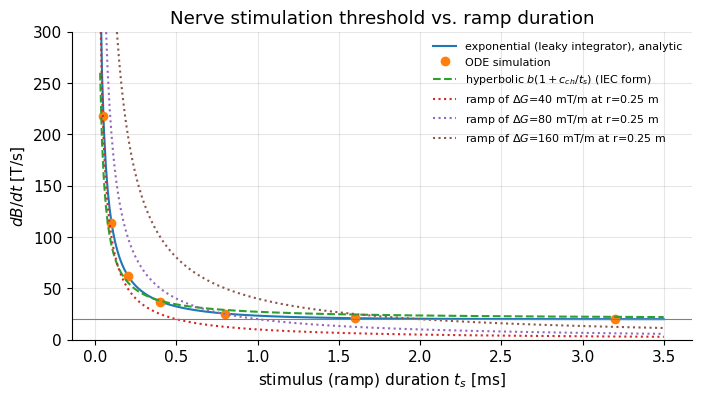

In [25]:
b_rheo, c_ch = 20.0, 0.36e-3            # rheobase [T/s], chronaxie [s]  (IEC whole-body model)
tau_m = c_ch / np.log(2)                # membrane time constant of the exponential model [s]

def fires(dBdt, t_s, dt=2e-6):
    """Integrate du/dt = -u/tau_m + |dB/dt|/(b tau_m) during a ramp of duration t_s; True if u reaches 1."""
    u = 0.0
    for _ in range(int(t_s / dt)):
        u += dt * (-u / tau_m + abs(dBdt) / (b_rheo * tau_m))
        if u >= 1:
            return True
    return False

def threshold_sim(t_s):
    lo, hi = 1.0, 2000.0                  # bisection on dB/dt [T/s]
    for _ in range(30):
        mid = 0.5 * (lo + hi)
        lo, hi = (lo, mid) if fires(mid, t_s) else (mid, hi)
    return hi

ts = np.array([0.05, 0.1, 0.2, 0.4, 0.8, 1.6, 3.2]) * 1e-3
th_sim = [threshold_sim(x) for x in ts]
ts_f = np.linspace(0.03e-3, 3.5e-3, 300)
plt.plot(ts_f * 1e3, b_rheo / (1 - np.exp(-ts_f / tau_m)), label="exponential (leaky integrator), analytic")
plt.plot(ts * 1e3, th_sim, "o", label="ODE simulation")
plt.plot(ts_f * 1e3, b_rheo * (1 + c_ch / ts_f), "--", label=r"hyperbolic $b(1+c_{ch}/t_s)$ (IEC form)")
# what the hardware produces: a ramp of DeltaG over t_s, seen at r = 0.25 m
r_eff = 0.25
for dG in (40e-3, 80e-3, 160e-3):
    plt.plot(ts_f * 1e3, dG * r_eff / ts_f, ":", label=fr"ramp of $\Delta G$={dG*1e3:.0f} mT/m at r={r_eff} m")
plt.axhline(b_rheo, color="gray", lw=0.8)
plt.ylim(0, 300); plt.xlabel(r"stimulus (ramp) duration $t_s$ [ms]"); plt.ylabel(r"$dB/dt$ [T/s]")
plt.title("Nerve stimulation threshold vs. ramp duration"); plt.legend(fontsize=8); plt.show()

The dots (ODE) lie on the exponential curve; the IEC hyperbola is close to it. The dotted lines are what a ramp of total change $\Delta G$ produces: a faster ramp (left) gives a higher $dB/dt$. Where a dotted curve lies above the threshold curve, the ramp stimulates.

**In gradient units.** Insert $dB/dt=\Delta G\,r/t_r$ into the hyperbolic threshold: stimulation occurs when

$$\Delta G > \underbrace{\frac{b\,c_{ch}}{r}}_{\Delta G_{min}}+\underbrace{\frac{b}{r}}_{SR_{min}}\,t_r .$$

In words: there is a minimum gradient *change* $\Delta G_{min}$ below which no ramp, however fast, stimulates; above it, the allowed change grows linearly with ramp time at rate $SR_{min}$.

where $\Delta G$ [T/m] is the gradient change during the ramp (e.g. $2G$ when an EPI readout flips from $-G$ to $+G$), $r$ [m] an effective distance from isocenter. This linear "$\Delta G$ vs $t_r$" form is how PNS is measured in volunteer studies.

In [26]:
r_eff = 0.25
dG_min, SR_min = b_rheo * c_ch / r_eff, b_rheo / r_eff
print(f"Delta G_min ≈ {dG_min*1e3:.0f} mT/m, SR_min ≈ {SR_min:.0f} T/m/s  (r_eff = {r_eff} m)")
for G_epi in (25e-3, 40e-3):
    dG = 2 * G_epi
    t_r_safe = max((dG - dG_min) / SR_min, 0)
    print(f"EPI readout ±{G_epi*1e3:.0f} mT/m: ramps shorter than {t_r_safe*1e3:.2f} ms stimulate "
          f"-> usable SR ≈ {dG/t_r_safe if t_r_safe>0 else np.inf:.0f} T/m/s (hardware: 200 T/m/s)")

Delta G_min ≈ 29 mT/m, SR_min ≈ 80 T/m/s  (r_eff = 0.25 m)
EPI readout ±25 mT/m: ramps shorter than 0.27 ms stimulate -> usable SR ≈ 189 T/m/s (hardware: 200 T/m/s)
EPI readout ±40 mT/m: ramps shorter than 0.64 ms stimulate -> usable SR ≈ 125 T/m/s (hardware: 200 T/m/s)


This is why a 200 T/m/s whole-body scanner usually cannot use its full slew rate in EPI: the patient's nerves, not the amplifier, set the limit. Scanners run a PNS prediction model for every sequence and block or slow down waveforms that would exceed the allowed level (e.g. 80 % of the predicted mean threshold in normal mode, see [B6](../pass2_deep_dive/B6_MRI_Safety.ipynb)).

> **🔧 Engineering reality:** PNS thresholds depend on the coil geometry, not only on $dB/dt$ at one point: coils whose field extends over large body regions (long, wide-bore whole-body coils) stimulate at lower slew rates than compact head coils. That is a second reason (besides $\eta^2/L$) why head-only gradients can run at 500–900 T/m/s, and why modern coil designs include PNS (computed with electromagnetic body models and nerve atlases) as an explicit design constraint. Thresholds vary several-fold between individuals.

## 11. Acoustic noise and mechanical vibration

### 11.1 Lorentz forces

A wire carrying current in a magnetic field feels the **Lorentz force**

$$\vec F = I_c\,\vec\ell\times\vec B_0 .$$

In words: the force is proportional to the current, the length of wire and the field, and points perpendicular to both the wire and $\vec B_0$.

where $\vec F$ [N] is the force, $I_c$ [A] the current, $\vec\ell$ [m] the wire segment (length and direction), $\vec B_0$ [T] the static field. Arcs running around the bore are perpendicular to $B_0$ and feel the full force.

In [27]:
for B0_ in (1.5, 3.0, 7.0):
    print(f"B0 = {B0_} T: 1 m of wire at 500 A feels {500*1.0*B0_:.0f} N  (≈ {500*B0_/9.81:.0f} kg weight)")

B0 = 1.5 T: 1 m of wire at 500 A feels 750 N  (≈ 76 kg weight)
B0 = 3.0 T: 1 m of wire at 500 A feels 1500 N  (≈ 153 kg weight)
B0 = 7.0 T: 1 m of wire at 500 A feels 3500 N  (≈ 357 kg weight)


Each gradient switch hits the coil with kilonewton forces, distributed over the windings. The coil deforms by micrometres and acts like a loudspeaker membrane. For a balanced design the *net* force and torque on the coil cancel, but the local forces still bend and twist it.

**Scaling.** The sound pressure $p$ is proportional to the force, i.e. to $I_cB_0$. Sound pressure level in decibels is $L_p=20\log_{10}(p/p_{ref})$ with $p_{ref}=20$ µPa, so

$$\Delta L_p = 20\log_{10}\frac{B_{0,2}}{B_{0,1}} + 20\log_{10}\frac{G_2}{G_1}\quad[\text{dB}].$$

In words: doubling the field strength (or the gradient amplitude) adds 6 dB — a doubling of sound pressure.

In [28]:
ref_level, ref_B0 = 100.0, 1.5             # e.g. a fast sequence measured at 100 dB at 1.5 T (illustrative)
for B0_ in (0.55, 1.5, 3.0, 7.0):
    print(f"same sequence at {B0_:4.2f} T: ≈ {ref_level + 20*np.log10(B0_/ref_B0):5.1f} dB")

same sequence at 0.55 T: ≈  91.3 dB
same sequence at 1.50 T: ≈ 100.0 dB
same sequence at 3.00 T: ≈ 106.0 dB
same sequence at 7.00 T: ≈ 113.4 dB


### 11.2 Spectrum, resonances and quiet sequences

The coil–cryostat structure has **mechanical resonances** (typically in the 0.5–3 kHz range). The sound spectrum is the gradient spectrum multiplied by an acoustic transfer function $H_{ac}(f)$ — a linear system again:

$$p(f)\approx H_{ac}(f)\,G(f).$$

In words: the gradient waveform's frequency content (its Fourier transform $G(f)$) is filtered by the mechanics; frequencies at a resonance are amplified.

where $G(f)$ is the Fourier transform of the gradient waveform ([Continuous FT and DFT](../refreshers/RM3_Continuous_FT_and_DFT.ipynb)), $H_{ac}$ [Pa per T/m] the (measured) transfer function. An EPI readout with echo spacing $t_{esp}$ is roughly a periodic square wave with fundamental frequency $1/(2t_{esp})$, so its sound is a loud tone — very loud if it hits a resonance. We model a toy transfer function with three resonances and compare echo spacings. We also apply the standard **A-weighting** curve (IEC 61672), which mimics the ear's lower sensitivity at low and very high frequencies.

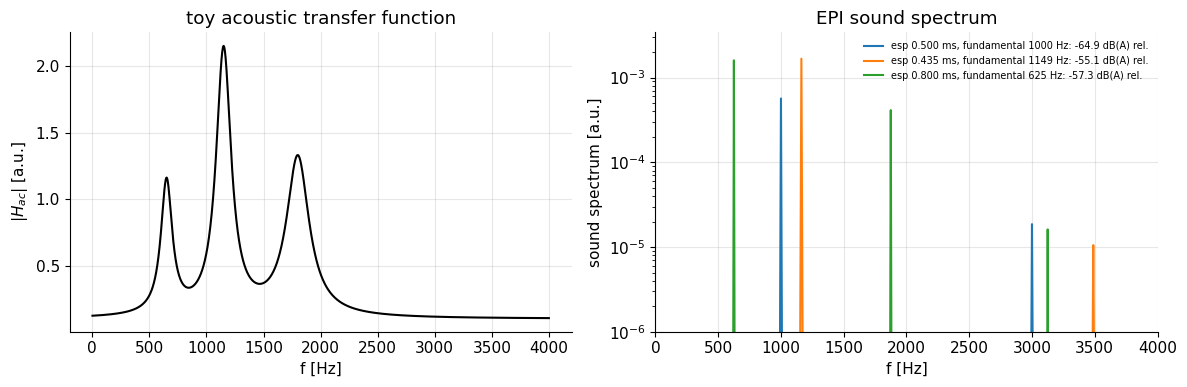

In [29]:
def a_weight_db(f):
    """IEC 61672 A-weighting [dB] at frequency f [Hz]."""
    f2 = np.asarray(f, float) ** 2
    ra = 12194**2 * f2**2 / ((f2 + 20.6**2) * np.sqrt((f2 + 107.7**2) * (f2 + 737.9**2)) * (f2 + 12194**2))
    return 20 * np.log10(np.maximum(ra, 1e-20)) + 2.0

def H_ac(f):
    """Toy acoustic transfer function: sum of three damped resonances (arbitrary units)."""
    res = [(650, 60, 1.0), (1150, 80, 2.0), (1800, 120, 1.2)]   # (centre [Hz], half-width [Hz], strength)
    return 0.1 + sum(s / (1 + ((f - fc) / w) ** 2) for fc, w, s in res)

dt_a = 5e-6
def epi_wave(esp, G=25e-3, n=128, ramp=0.1e-3):
    t, lobe = trapezoid(G, ramp, esp - 2 * ramp, dt=dt_a, pad=0)
    return np.concatenate([lobe * (-1) ** k for k in range(n)])

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
f_ax = np.linspace(1, 4000, 2000)
ax[0].plot(f_ax, H_ac(f_ax), "k"); ax[0].set(xlabel="f [Hz]", ylabel=r"$|H_{ac}|$ [a.u.]", title="toy acoustic transfer function")
for esp in (0.50e-3, 0.435e-3, 0.80e-3):
    w = epi_wave(esp)
    Gf = np.abs(np.fft.rfft(w)) * dt_a
    f = np.fft.rfftfreq(len(w), dt_a)
    pf = H_ac(f) * Gf
    LA = 10 * np.log10(np.sum((pf * 10 ** (a_weight_db(f) / 20)) ** 2) + 1e-30)   # A-weighted level (relative)
    ax[1].semilogy(f, pf + 1e-9, lw=1.5, label=f"esp {esp*1e3:.3f} ms, fundamental {1/(2*esp):.0f} Hz: {LA:.1f} dB(A) rel.")
ax[1].set(xlim=(0, 4000), ylim=(1e-6, None), xlabel="f [Hz]", ylabel="sound spectrum [a.u.]", title="EPI sound spectrum")
ax[1].legend(fontsize=7); plt.tight_layout(); plt.show()

The 0.435 ms echo spacing puts the EPI fundamental (1150 Hz) right on the strongest resonance and is several dB louder than the others (the relative dB(A) values in the legend). Real scanners publish **forbidden echo-spacing ranges** for EPI for exactly this reason — at resonance the coil vibrates so strongly that it can be damaged and that vibration artifacts appear.

**Quiet sequences** attack the force spectrum: soften the ramps (lower slew rate removes high-frequency content), use sinusoidal instead of trapezoidal waveforms, keep gradients nearly constant (zero-echo-time / silent sequences, which only rotate the gradient direction in tiny steps), or avoid the resonance bands.

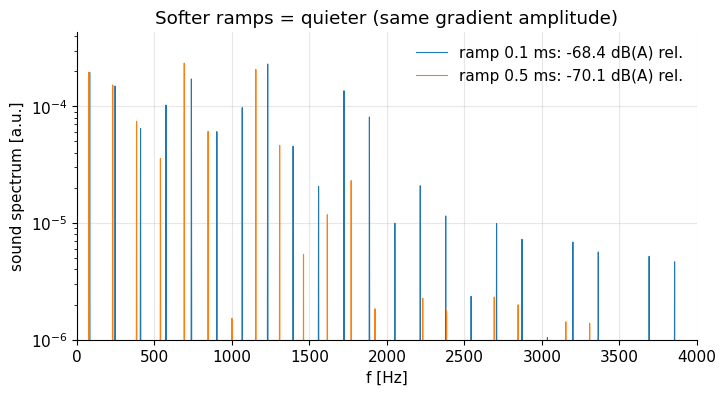

In [30]:
# Same lobe area, sharp vs soft ramps: high-frequency content (and A-weighted loudness)
for ramp in (0.1e-3, 0.5e-3):
    _, lobe = trapezoid(20e-3, ramp, 2e-3 - ramp, dt=dt_a, pad=2e-3)
    train = np.tile(np.concatenate([lobe, -lobe]), 20)
    Gf = np.abs(np.fft.rfft(train)) * dt_a; f = np.fft.rfftfreq(len(train), dt_a)
    pf = H_ac(f) * Gf
    LA = 10 * np.log10(np.sum((pf * 10 ** (a_weight_db(f) / 20)) ** 2))
    plt.semilogy(f, pf + 1e-9, lw=0.8, label=f"ramp {ramp*1e3:.1f} ms: {LA:.1f} dB(A) rel.")
plt.xlim(0, 4000); plt.ylim(1e-6, None); plt.xlabel("f [Hz]"); plt.ylabel("sound spectrum [a.u.]")
plt.title("Softer ramps = quieter (same gradient amplitude)"); plt.legend(); plt.show()

Slower ramps suppress the harmonics that fall into the resonance band, lowering the A-weighted level by many dB — at the cost of longer gradient lobes.

> **🔧 Engineering reality:** Fast sequences on clinical scanners typically produce 100–120 dB(A) inside the bore, so hearing protection is mandatory ([B6 Safety](../pass2_deep_dive/B6_MRI_Safety.ipynb)). Countermeasures: vacuum-enclosed gradient coils (no air to carry sound to the bore), mounting the coil on vibration isolators, balanced force designs, damping materials in the bore liner, and active noise cancellation in headphones. Vibration also matters for image quality (diffusion imaging is sensitive to table/coil vibration) and for the cryostat: eddy currents in vibrating cold metal heat it and boil off helium.

## 12. Typical gradient performance

| System class (examples) | $G_{max}$ [mT/m] | $SR_{max}$ [T/m/s] | rise time 0→$G_{max}$ | remark |
|---|---|---|---|---|
| Low-field / entry-level whole-body | 20–45 | 50–150 | ~0.3–0.5 ms | cost-optimized |
| High-end clinical 1.5 T / 3 T whole-body (e.g. Siemens MAGNETOM Prisma: 80 mT/m, 200 T/m/s) | 45–80 | 150–200 | 0.3–0.4 ms | PNS-limited in EPI |
| Connectome-class research whole-body (MGH-USC Connectome, 3 T) | 300 | 200 | 1.5 ms | diffusion MRI |
| Connectome 2.0 (head-focused, 3 T) | ~500 | ~600 | ~0.8 ms | microstructure imaging |
| Head-only high-performance (e.g. GE MAGNUS at 3 T; Siemens "Impulse" at 7 T) | ~200 | 500–900 | 0.2–0.4 ms | small radius, high $\eta^2/L$ |

Values are approximate and taken from published descriptions; manufacturers revise them. The pattern follows from this chapter: smaller radius → higher $\eta^2/L$ and higher PNS thresholds → much faster gradients; whole-body coils trade speed for a large patient bore.

In [31]:
rows = [("entry level", 33e-3, 100), ("clinical high-end", 80e-3, 200), ("Connectome", 300e-3, 200),
        ("Connectome 2.0", 500e-3, 600), ("head-only", 200e-3, 900)]
A_test = 1.2e-5   # ~1 mm phase-encode area [T s/m]
print(f"{'system':18s} {'rise [ms]':>9s} {'1 mm PE lobe [ms]':>18s}")
for name, Gm, sr in rows:
    print(f"{name:18s} {Gm/sr*1e3:9.2f} {min_time_lobe(A_test, Gm, sr)[2]*1e3:18.3f}")

system             rise [ms]  1 mm PE lobe [ms]
entry level             0.33              0.694
clinical high-end       0.40              0.490
Connectome              1.50              0.490
Connectome 2.0          0.83              0.283
head-only               0.22              0.231


## Key takeaways

- A gradient coil makes $B_z$ vary linearly in space ($B_z=B_0+\vec G\cdot\vec r$); Maxwell's equations force accompanying transverse **concomitant fields** that scale as $G^2r^2/B_0$.
- Classic designs (Maxwell pair, Golay saddles) have been replaced by distributed "fingerprint" windings from **target-field / stream-function** optimization — a regularized least-squares problem.
- Electrically, the coil is $L$ + $R_{coil}$ with efficiency $\eta$: $G_{max}=\eta I_{max}$ and $SR_{max}\approx\eta V_{max}/L$; for a fixed geometry $G_{max}SR_{max}=(\eta^2/L)V_{max}I_{max}$, and $\eta^2/L\propto a^{-5}$ explains why head gradients are so fast.
- Minimum-time lobes are triangles (slew-limited, $T=2\sqrt{A/SR}$) or trapezoids ($T=A/G_{max}+G_{max}/SR$).
- Heating goes with $I_{rms}^2R_{coil}$ (kW, water-cooled); eddy currents (Lenz) behave like a sum of decaying exponentials and are removed by active shielding plus **pre-emphasis** (an inverse filter).
- Non-linearity distorts images away from isocenter (corrected in reconstruction); **PNS** (rheobase ~20 T/s, chronaxie ~0.36 ms) and **acoustic noise/vibration** ($\propto I_cB_0$, mechanical resonances) often limit what the hardware could otherwise do.

## Check your understanding

1. A gradient coil has $\eta=0.12$ mT/m/A and $L=0.9$ mH and is driven by a 1500 V / 600 A amplifier. What are $G_{max}$, $SR_{max}$ and the rise time to $G_{max}$?

<details><summary>Answer</summary>

$G_{max}=0.12\times600=72$ mT/m. $SR_{max}=\eta V_{max}/L = 1.2\times10^{-4}\times1500/0.9\times10^{-3}=200$ T/m/s (slightly less at full current because of $R_{coil}I_c$). Rise time $=0.072/200=0.36$ ms.

</details>

2. You need a gradient lobe of area 4 mT·ms/m on a system with 40 mT/m and 200 T/m/s. Triangle or trapezoid, and how long?

<details><summary>Answer</summary>

$G_{max}^2/SR=(0.04)^2/200=8\times10^{-6}$ T s/m = 8 mT·ms/m > 4, so a triangle suffices: peak $\sqrt{A\,SR}=\sqrt{4\times10^{-6}\cdot200}=28$ mT/m, duration $2\sqrt{A/SR}=2\sqrt{2\times10^{-8}}=0.28$ ms.

</details>

3. Why does doubling the number of turns of a gradient coil (same amplifier) double $G_{max}$ but halve $SR_{max}$?

<details><summary>Answer</summary>

$\eta\propto N_t$ so $G_{max}=\eta I_{max}$ doubles. The inductance grows as $N_t^2$ (4×), so $SR_{max}=\eta V_{max}/L$ changes by $2/4=1/2$. The product $G_{max}SR_{max}$ stays the same.

</details>

4. After a gradient lobe ends you observe a small negative gradient decaying with a time constant of ~20 ms. What is it, where does it come from, and how do scanners deal with it?

<details><summary>Answer</summary>

An eddy-current tail: the ramp-down induced currents in conducting cryostat structures that oppose the change (Lenz), and they decay with the L/R time constant of that structure. Active shielding reduces it ~100×; the remainder is compensated by pre-emphasis (an over-shooting input filter with matching exponential terms), and B0 eddy terms by frequency compensation.

</details>

5. Why are concomitant fields a bigger problem at 0.55 T than at 3 T, and why do they not cancel for a bipolar gradient pair?

<details><summary>Answer</summary>

The concomitant frequency offset is $\approx\bar\gamma G^2r^2/(2B_0)$: inversely proportional to $B_0$, so 5.5× larger at 0.55 T for the same gradient. It depends on $G^2$, which is positive for both lobes of a bipolar pair, so the phases add instead of cancelling.

</details>

6. An EPI readout switches from −30 to +30 mT/m. With $\Delta G_{min}\approx29$ mT/m and $SR_{min}\approx80$ T/m/s, what is the shortest ramp that avoids stimulation, and what slew rate does that correspond to?

<details><summary>Answer</summary>

$\Delta G=60$ mT/m. Stimulation if $\Delta G>\Delta G_{min}+SR_{min}t_r$, so we need $t_r\ge(0.060-0.029)/80\approx0.39$ ms, i.e. a slew rate of at most $0.060/0.39\approx155$ T/m/s — below a 200 T/m/s hardware limit.

</details>

---
*New chapter written for this adaptation; see references below. Material on gradient non-linearity, acoustic noise and eddy currents was harvested from the original chapters "MRI System", "Magnetic Fields in MRI" and "Artifacts" (P. Larson, "Principles of MRI", MIT License) and extended with derivations and simulations.*

**References**
- D. W. McRobbie, E. A. Moore, M. J. Graves, M. R. Prince, *MRI from Picture to Proton*, 3rd ed., Cambridge University Press, 2017 (gradient hardware, PNS, acoustic noise).
- M. A. Bernstein, K. F. King, X. J. Zhou, *Handbook of MRI Pulse Sequences*, Elsevier, 2004 (gradient lobes, eddy currents and pre-emphasis, concomitant fields).
- R. W. Brown, Y.-C. N. Cheng, E. M. Haacke, M. R. Thompson, R. Venkatesan, *Magnetic Resonance Imaging: Physical Principles and Sequence Design*, 2nd ed., Wiley, 2014 (gradient coil design, Maxwell pair).
- R. Turner, "A target field approach to optimal coil design", *J. Phys. D: Appl. Phys.* 19, L147 (1986).
- IEC 60601-2-33, *Medical electrical equipment – Part 2-33: Particular requirements for the basic safety and essential performance of magnetic resonance equipment for medical diagnosis* (PNS limits).